# TP4: Training with SGD, Mini-batches and Momentum

A typical training pipeline:
* Prepare the dataset: split it, normalize it to zero mean and unit variance.
* Define the model, the loss function and the optimizer; initialize the parameters.
* Loop until a stopping criterion:
  * take a mini-batch of data;
  * compute the forward pass;
  * compute the loss on the predictions and the labels;
  * update the parameters with the optimizer.
* Tune the hyperparameters: learning rate, batch size, number of epochs, optimizer.

PyTorch gives one object for each part (`DataLoader`, `nn.Module`, loss, `optim`), so we can change one part and keep the others.

**This TP**
1. **Follow along (Parts 0–4).** On a toy problem, train the same model three ways: SGD with **1 example per update**, **mini-batch** SGD, and mini-batch SGD with **momentum**. Then compare the three on one figure. Part 4 prepares MNIST for the exercises.
2. **Exercises (to submit).** On MNIST, and optionally CIFAR-10: experiment with the learning rate, the batch size, momentum and other optimizers, learning rate schedules and batch normalization. After each experiment, write what you observe and explain it in the cell.

**Runtime:** Colab with a GPU (Runtime → Change runtime type → T4 GPU).

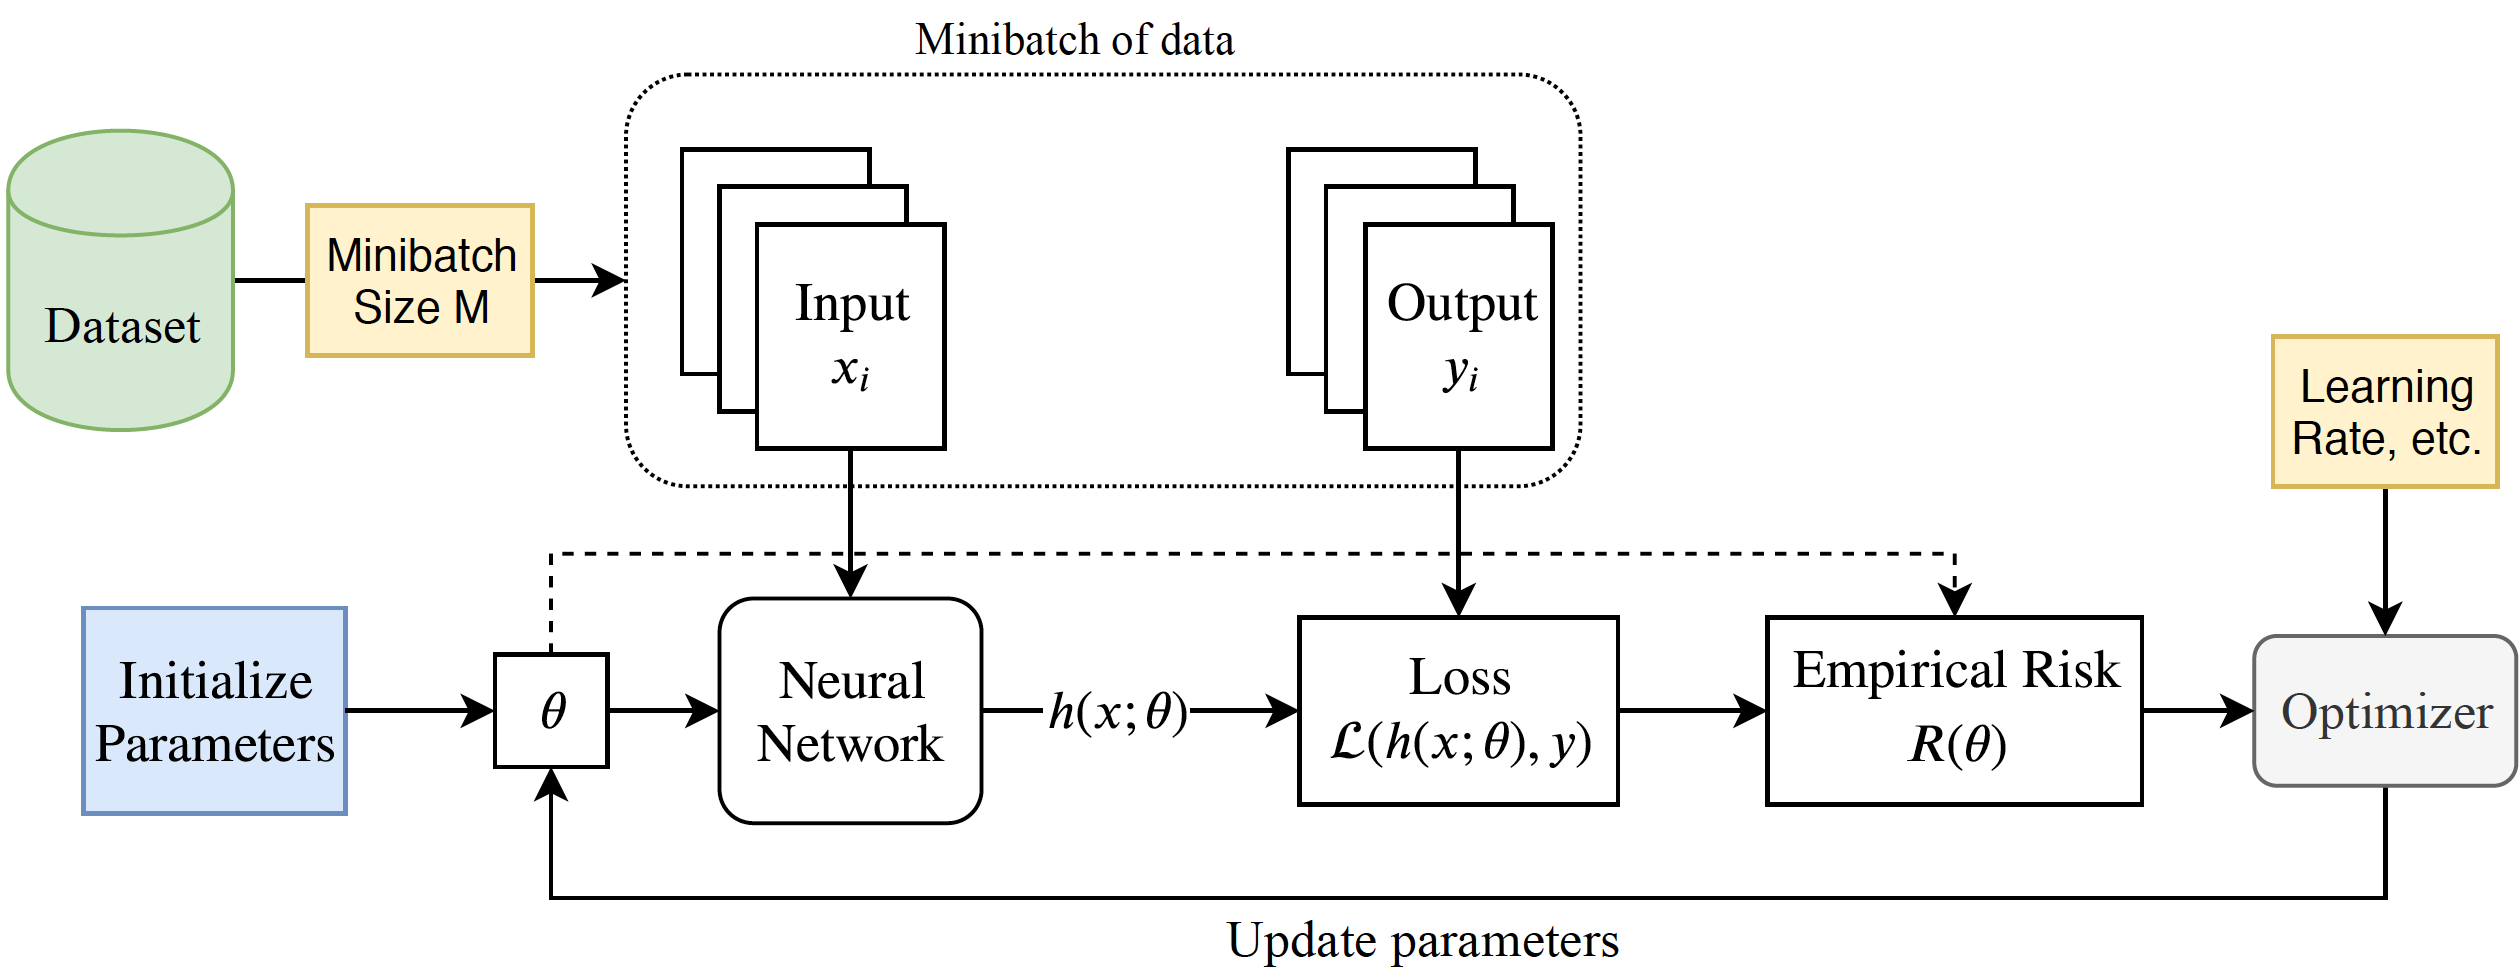

## 0 · Setup

In [1]:
import math, time, random
import numpy as np
import torch
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets
import matplotlib.pyplot as plt

SEED = 1234
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.14.1+cpu | device: cpu


## 1 · A toy problem: linear regression

1,000 points $(x, y)$ with $y = 3x + 2 + \text{noise}$ and $x$ between 0 and 5. The model is one linear unit, $\hat y = w x + b$ (`nn.Linear(1, 1)`), trained with the mean squared error
$$J(w, b) = \frac{1}{m}\sum_{i=1}^{m}\big(w x^{(i)} + b - y^{(i)}\big)^2 .$$
With only two parameters we can draw every step of the optimizer on the contour plot of $J$.

Inputs and targets are tensors of shape $(m, 1)$: one example per row.

least squares: w = 2.989, b = 2.062, J = 0.9493


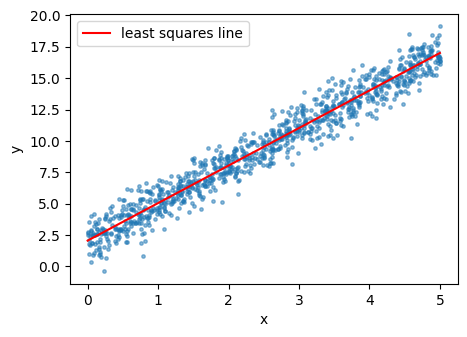

In [2]:
m = 1000
gen = torch.Generator().manual_seed(0)
x_toy = 5 * torch.rand(m, 1, generator=gen)
y_toy = 3 * x_toy + 2 + torch.randn(m, 1, generator=gen)

# the best possible (w, b), by least squares, to measure how far each run is from it
A = torch.cat([x_toy, torch.ones(m, 1)], dim=1)
w_best, b_best = torch.linalg.lstsq(A, y_toy).solution.flatten().tolist()
J_best = ((w_best * x_toy + b_best - y_toy) ** 2).mean().item()
print(f"least squares: w = {w_best:.3f}, b = {b_best:.3f}, J = {J_best:.4f}")

plt.figure(figsize=(5, 3.5))
plt.scatter(x_toy, y_toy, s=6, alpha=0.5)
plt.plot([0, 5], [b_best, 5 * w_best + b_best], "r", label="least squares line")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.show()

Every run starts from the same point, $w = 0$, $b = 8$, uses the same learning rate $\alpha = 0.01$ and trains for 20 epochs. Only the **batch size** and **momentum** change.

`train_toy` is the PyTorch training loop. After every update it records:
- the loss $J(w, b)$ on **all** 1,000 points (to compare runs fairly, even when they update on different numbers of examples);
- the values of $w$ and $b$ (to draw the path).

In [3]:
def full_loss(model):
    with torch.no_grad():
        return ((model(x_toy) - y_toy) ** 2).mean().item()

def train_toy(batch_size, lr=0.01, momentum=0.0, epochs=20, seed=0):
    model = nn.Linear(1, 1)
    with torch.no_grad():                              # same starting point for every run
        model.weight.fill_(0.0)
        model.bias.fill_(8.0)
    loss_fn = nn.MSELoss()
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    loader = DataLoader(TensorDataset(x_toy, y_toy), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))

    hist = {"loss": [full_loss(model)], "w": [0.0], "b": [8.0], "epoch_loss": [full_loss(model)], "time": 0.0}
    for epoch in range(epochs):
        for x_t, y_t in loader:
            start = time.perf_counter()
            loss = loss_fn(model(x_t), y_t)            # forward pass and loss on the mini-batch
            optimizer.zero_grad()
            loss.backward()                            # backpropagation
            optimizer.step()                           # update w and b
            hist["time"] += time.perf_counter() - start
            hist["loss"].append(full_loss(model))      # record (not part of training)
            hist["w"].append(model.weight.item()); hist["b"].append(model.bias.item())
        hist["epoch_loss"].append(full_loss(model))
        if (epoch + 1) % 1 == 0:
            print(f"epoch {epoch + 1:2d} | J = {hist['epoch_loss'][-1]:.4f} | w = {model.weight.item():.3f}, b = {model.bias.item():.3f}")
    print(f"updates: {len(hist['loss']) - 1} | training time: {hist['time']:.2f} s")
    return hist

## 2 · Three ways to train

### 2.1 SGD with one example per update
`batch_size=1`: each update uses the gradient of **one** randomly chosen example. One epoch = 1,000 updates.

In [4]:
hist_sgd = train_toy(batch_size=1)

epoch  1 | J = 1.0230 | w = 2.891, b = 2.075
epoch  2 | J = 0.9702 | w = 3.026, b = 2.103
epoch  3 | J = 0.9785 | w = 3.060, b = 2.020
epoch  4 | J = 1.0928 | w = 3.165, b = 1.898
epoch  5 | J = 0.9849 | w = 3.022, b = 2.163
epoch  6 | J = 0.9735 | w = 3.021, b = 2.131
epoch  7 | J = 1.0184 | w = 2.892, b = 2.084
epoch  8 | J = 0.9566 | w = 3.013, b = 2.081
epoch  9 | J = 1.0841 | w = 2.855, b = 2.087
epoch 10 | J = 0.9812 | w = 3.055, b = 2.048
epoch 11 | J = 1.0366 | w = 3.056, b = 2.174
epoch 12 | J = 1.0330 | w = 3.068, b = 2.130
epoch 13 | J = 1.0759 | w = 3.090, b = 2.132
epoch 14 | J = 1.0242 | w = 2.915, b = 1.997
epoch 15 | J = 1.0084 | w = 2.887, b = 2.127
epoch 16 | J = 1.3911 | w = 2.786, b = 1.976
epoch 17 | J = 1.0375 | w = 2.872, b = 2.112
epoch 18 | J = 0.9864 | w = 3.090, b = 1.933
epoch 19 | J = 0.9582 | w = 3.017, b = 2.076
epoch 20 | J = 0.9500 | w = 2.972, b = 2.112
updates: 20000 | training time: 7.22 s


The loss gets close to its minimum ($J \approx 1.05$, the noise level) within the first epoch, but then it **does not settle**: each update follows a single example, so $w$ and $b$ keep jumping around the minimum.

### 2.2 Mini-batch SGD
`batch_size=32`: each update uses the average gradient of 32 examples. One epoch = 32 updates (the last mini-batch has 8 examples).

In [5]:
hist_mb = train_toy(batch_size=32)

epoch  1 | J = 8.3765 | w = 1.290, b = 7.434
epoch  2 | J = 6.4393 | w = 1.595, b = 6.707
epoch  3 | J = 4.9947 | w = 1.744, b = 6.033
epoch  4 | J = 3.9405 | w = 1.904, b = 5.466
epoch  5 | J = 3.1727 | w = 2.041, b = 4.983
epoch  6 | J = 2.5936 | w = 2.240, b = 4.604
epoch  7 | J = 2.1565 | w = 2.310, b = 4.232
epoch  8 | J = 1.8781 | w = 2.474, b = 3.953
epoch  9 | J = 1.6184 | w = 2.477, b = 3.674
epoch 10 | J = 1.4506 | w = 2.593, b = 3.461
epoch 11 | J = 1.3177 | w = 2.637, b = 3.265
epoch 12 | J = 1.2207 | w = 2.670, b = 3.093
epoch 13 | J = 1.1542 | w = 2.734, b = 2.958
epoch 14 | J = 1.1020 | w = 2.739, b = 2.826
epoch 15 | J = 1.0610 | w = 2.787, b = 2.724
epoch 16 | J = 1.0336 | w = 2.810, b = 2.636
epoch 17 | J = 1.0126 | w = 2.829, b = 2.556
epoch 18 | J = 0.9964 | w = 2.867, b = 2.491
epoch 19 | J = 0.9886 | w = 2.900, b = 2.435
epoch 20 | J = 0.9762 | w = 2.906, b = 2.381
updates: 640 | training time: 0.20 s


The updates are much less noisy, and each one is computed for 32 examples at once (vectorized). But with the same $\alpha$ there are 32 times fewer updates per epoch, so after 20 epochs the run is still on its way to the minimum.

### 2.3 Mini-batch SGD with momentum
Same mini-batches, with `momentum=0.9`. PyTorch’s update is
$$\mathbf{v} \leftarrow 0.9\,\mathbf{v} + \nabla J^{\{t\}}, \qquad \theta \leftarrow \theta - \alpha\,\mathbf{v}.$$

In [6]:
hist_mom = train_toy(batch_size=64, momentum=0.9)

epoch  1 | J = 6.1264 | w = 1.434, b = 5.922
epoch  2 | J = 1.4561 | w = 2.634, b = 3.438
epoch  3 | J = 1.0152 | w = 3.024, b = 2.225
epoch  4 | J = 0.9865 | w = 3.092, b = 1.923
epoch  5 | J = 0.9673 | w = 3.071, b = 1.918
epoch  6 | J = 0.9700 | w = 3.055, b = 2.005
epoch  7 | J = 0.9650 | w = 3.032, b = 2.063
epoch  8 | J = 1.0744 | w = 3.099, b = 2.102
epoch  9 | J = 0.9555 | w = 3.013, b = 2.073
epoch 10 | J = 0.9531 | w = 2.964, b = 2.075
epoch 11 | J = 0.9698 | w = 2.941, b = 2.056
epoch 12 | J = 0.9842 | w = 2.928, b = 2.052
epoch 13 | J = 0.9596 | w = 2.954, b = 2.062
epoch 14 | J = 0.9543 | w = 3.008, b = 2.081
epoch 15 | J = 0.9756 | w = 3.041, b = 2.074
epoch 16 | J = 0.9545 | w = 3.009, b = 2.079
epoch 17 | J = 0.9496 | w = 2.985, b = 2.056
epoch 18 | J = 0.9775 | w = 3.036, b = 2.098
epoch 19 | J = 0.9519 | w = 3.004, b = 2.070
epoch 20 | J = 0.9505 | w = 3.005, b = 2.048
updates: 320 | training time: 0.14 s


## 3 · Comparing the three runs
Three views of the same three runs:
1. the loss after each **epoch** (above its minimum $J_{\text{best}}$, on a log scale);
2. the loss after each **update**;
3. the **path** of $(w, b)$ on the contours of $J$.

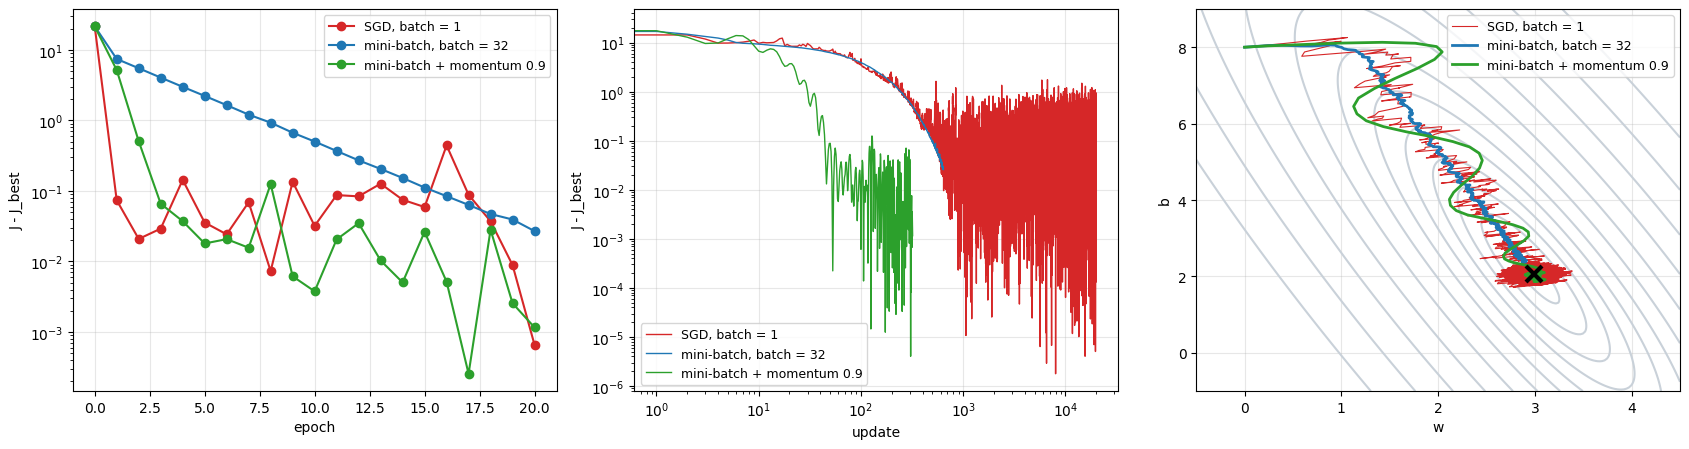

SGD, batch = 1               updates:  20000 | time: 7.22 s | final J - J_best: 0.0007
mini-batch, batch = 32       updates:    640 | time: 0.20 s | final J - J_best: 0.0269
mini-batch + momentum 0.9    updates:    320 | time: 0.14 s | final J - J_best: 0.0012


In [7]:
runs = {"SGD, batch = 1": hist_sgd, "mini-batch, batch = 32": hist_mb, "mini-batch + momentum 0.9": hist_mom}
colors = ["tab:red", "tab:blue", "tab:green"]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for (label, h), c in zip(runs.items(), colors):
    ax[0].plot(np.array(h["epoch_loss"]) - J_best + 1e-6, "o-", color=c, label=label)
    ax[1].plot(np.array(h["loss"]) - J_best + 1e-6, color=c, lw=1, label=label)
ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("J - J_best")
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("update"); ax[1].set_ylabel("J - J_best")

W, B = torch.meshgrid(torch.linspace(-0.5, 4.5, 200), torch.linspace(-1, 9, 200), indexing="xy")
# J(w, b) on the grid, from the averages of x^2, x, xy, y, y^2 (expand the square)
Ex2, Ex, Exy, Ey, Ey2 = [t.mean().item() for t in (x_toy ** 2, x_toy, x_toy * y_toy, y_toy, y_toy ** 2)]
Jgrid = W ** 2 * Ex2 + 2 * W * B * Ex + B ** 2 - 2 * W * Exy - 2 * B * Ey + Ey2
ax[2].contour(W, B, Jgrid, levels=np.geomspace(1.1, 60, 12), colors="#C9D1D9")
for (label, h), c in zip(runs.items(), colors):
    ax[2].plot(h["w"], h["b"], color=c, lw=0.8 if "= 1" in label else 2, label=label)
ax[2].plot(w_best, b_best, "kx", ms=12, mew=3)
ax[2].set_xlabel("w"); ax[2].set_ylabel("b")
for a in ax:
    a.grid(alpha=0.3); a.legend(fontsize=9)
plt.tight_layout(); plt.show()

for label, h in runs.items():
    print(f"{label:28s} updates: {len(h['loss']) - 1:6d} | time: {h['time']:.2f} s | final J - J_best: {h['epoch_loss'][-1] - J_best:.4f}")

**What the figure shows**
- **SGD, batch = 1** (red): the most updates per epoch, so the fastest progress per epoch at first. Its path is a cloud of jumps: it reaches the minimum region quickly and then wanders around it. It also takes the most time: 1,000 small updates per epoch, one Python loop iteration each.
- **Mini-batch, batch = 32** (blue): a smooth path, with few updates per epoch. The contours are long, narrow ellipses (a **ravine**: $w$ and $b$ are strongly correlated because $x$ is not centered), and with $\alpha = 0.01$ the run moves slowly along the long direction.
- **Mini-batch + momentum** (green): the same number of updates as blue, but the velocity accumulates the steps along the ravine, so it reaches the minimum much sooner.

The run with batch = 1 would need a **decaying** learning rate to settle, and the run with batch = 32 a larger one or momentum: the batch size, the learning rate and momentum have to be chosen together. The exercises explore this on real data.

## 4 · Tools for the exercises: MNIST

### 4.1 The data
MNIST: 28 × 28 grayscale images of handwritten digits, 10 classes. We keep 54,000 images for training, 6,000 for validation, and the 10,000 test images for the very end. Each image is flattened to a row of 784 values and normalized with the mean and standard deviation of the training pixels. The tensors are prepared once, so the `DataLoader` is fast.

100%|██████████| 9.91M/9.91M [00:00<00:00, 59.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.83MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 15.3MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.01MB/s]


train (54000, 784) | val (6000, 784) | test (10000, 784)


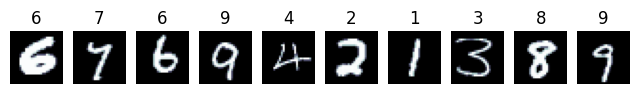

In [8]:
train_full = datasets.MNIST(root="data", train=True, download=True)
test_full = datasets.MNIST(root="data", train=False, download=True)

perm = torch.randperm(60000, generator=torch.Generator().manual_seed(42))
pixels = train_full.data[perm[:54000]].float() / 255
mean, std = pixels.mean(), pixels.std()                  # training statistics only

def prep(images):
    return ((images.float() / 255 - mean) / std).reshape(len(images), -1)   # (m, 784)

X_all, y_all = prep(train_full.data), train_full.targets
X_train, y_train = X_all[perm[:54000]], y_all[perm[:54000]]
X_val, y_val = X_all[perm[54000:]], y_all[perm[54000:]]
X_test, y_test = prep(test_full.data), test_full.targets
print("train", tuple(X_train.shape), "| val", tuple(X_val.shape), "| test", tuple(X_test.shape))

plt.figure(figsize=(8, 2.4))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap="bone"); plt.title(int(y_train[i])); plt.axis("off")
plt.show()

def make_loader(batch_size=64, n_train=None, seed=0):
    # mini-batches of the first n_train training examples (all of them if n_train is None)
    X, y = (X_train, y_train) if n_train is None else (X_train[:n_train], y_train[:n_train])
    return DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=True,
                      generator=torch.Generator().manual_seed(seed))

### 4.2 The model
A multilayer perceptron 784 → 128 → 100 → 10 with ReLU, returning logits. With `batch_norm=True`, an `nn.BatchNorm1d` layer comes after each hidden linear layer, before the ReLU, and the linear layer has no bias (batch norm’s $\beta$ replaces it). `make_model(seed)` gives the same initial weights for the same seed, so that two runs differ only by what you change.

In [9]:
class MLP(nn.Module):
    def __init__(self, n_in=784, hidden=(128, 100), n_out=10, batch_norm=False):
        super().__init__()
        layers = []
        for h in hidden:
            layers.append(nn.Linear(n_in, h, bias=not batch_norm))
            if batch_norm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            n_in = h
        layers.append(nn.Linear(n_in, n_out))
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        return self.layers(x)

def make_model(seed=0, **kwargs):
    torch.manual_seed(seed)
    return MLP(**kwargs).to(device)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(make_model())
print(f"{count_parameters(make_model()):,} parameters | with batch norm: {count_parameters(make_model(batch_norm=True)):,}")

MLP(
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=100, bias=True)
    (3): ReLU()
    (4): Linear(in_features=100, out_features=10, bias=True)
  )
)
114,390 parameters | with batch norm: 114,618


### 4.3 Training and evaluation
- `evaluate(model, X, y)` returns the loss and the accuracy (%) on a dataset, in evaluation mode.
- `fit(model, optimizer, loader, epochs, scheduler=None)` trains with mini-batches and returns a history: the loss of every update (`"step_loss"`), and per epoch the training loss, the validation loss and accuracy, the learning rate and the elapsed time. If the loss becomes `nan` or `inf`, the run has **diverged**: `fit` stops and sets `"diverged"` to `True`. A scheduler, if given, is stepped once per epoch.
- `plot_history({label: history, ...})` plots the smoothed loss of every update and the validation accuracy per epoch.

In [10]:
def evaluate(model, X, y, batch_size=2000):
    model.eval()
    loss_fn = nn.CrossEntropyLoss(reduction="sum")
    total, correct = 0.0, 0
    with torch.inference_mode():
        for i in range(0, len(X), batch_size):
            xb, yb = X[i:i + batch_size].to(device), y[i:i + batch_size].to(device)
            logits = model(xb)
            total += loss_fn(logits, yb).item()
            correct += (logits.argmax(dim=1) == yb).sum().item()
    return total / len(X), 100 * correct / len(X)

def fit(model, optimizer, loader, epochs, scheduler=None, verbose=True):
    loss_fn = nn.CrossEntropyLoss()
    hist = {"step_loss": [], "train_loss": [], "val_loss": [], "val_acc": [], "lr": [], "time": [], "diverged": False}
    start = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        hist["lr"].append(optimizer.param_groups[0]["lr"])
        total, count = 0.0, 0
        for X_t, y_t in loader:
            X_t, y_t = X_t.to(device), y_t.to(device)
            loss = loss_fn(model(X_t), y_t)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            hist["step_loss"].append(loss.item())
            total += loss.item() * len(y_t); count += len(y_t)
            if not math.isfinite(loss.item()):
                hist["diverged"] = True
                break
        if scheduler is not None:
            scheduler.step()
        val_loss, val_acc = evaluate(model, X_val, y_val)
        hist["train_loss"].append(total / count); hist["val_loss"].append(val_loss); hist["val_acc"].append(val_acc)
        hist["time"].append(time.perf_counter() - start)
        if verbose:
            print(f"epoch {epoch + 1:2d} | lr {hist['lr'][-1]:.2e} | train loss {total / count:.4f} | "
                  f"val loss {val_loss:.4f} | val acc {val_acc:.2f}% | {hist['time'][-1]:.1f} s")
        if hist["diverged"]:
            print("diverged (loss is nan or inf): stopping")
            break
    return hist

def smooth(values, beta=0.98):
    # exponentially weighted average with bias correction (Lecture 4)
    v, out = 0.0, []
    for t, x in enumerate(values, 1):
        x = x if math.isfinite(x) else 10.0
        v = beta * v + (1 - beta) * x
        out.append(v / (1 - beta ** t))
    return out

def plot_history(hists, title="", ylim=(0, 2.5)):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for label, h in hists.items():
        ax[0].plot(smooth(h["step_loss"]), label=label + (" (diverged)" if h["diverged"] else ""))
        ax[1].plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], "o-", label=label)
    ax[0].set_ylim(*ylim); ax[0].set_xlabel("update"); ax[0].set_ylabel("training loss (smoothed)")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation accuracy (%)")
    for a in ax:
        a.grid(alpha=0.3); a.legend(fontsize=9)
    fig.suptitle(title); plt.show()

### 4.4 Check that everything works
One run: Adam, $\alpha = 10^{-3}$, mini-batches of 64, 2 epochs on 10,000 training examples.

epoch  1 | lr 1.00e-03 | train loss 0.2744 | val loss 0.1607 | val acc 95.10% | 3.3 s
epoch  2 | lr 1.00e-03 | train loss 0.1175 | val loss 0.1264 | val acc 96.23% | 5.6 s
epoch  3 | lr 1.00e-03 | train loss 0.0835 | val loss 0.0965 | val acc 97.00% | 8.0 s
epoch  4 | lr 1.00e-03 | train loss 0.0623 | val loss 0.0784 | val acc 97.72% | 11.6 s
epoch  5 | lr 1.00e-03 | train loss 0.0517 | val loss 0.0827 | val acc 97.57% | 14.1 s
epoch  6 | lr 1.00e-03 | train loss 0.0423 | val loss 0.0913 | val acc 97.40% | 16.5 s
epoch  7 | lr 1.00e-03 | train loss 0.0346 | val loss 0.0991 | val acc 97.18% | 19.2 s
epoch  8 | lr 1.00e-03 | train loss 0.0286 | val loss 0.1104 | val acc 97.15% | 22.0 s
epoch  9 | lr 1.00e-03 | train loss 0.0285 | val loss 0.1036 | val acc 97.23% | 25.5 s
epoch 10 | lr 1.00e-03 | train loss 0.0210 | val loss 0.1157 | val acc 97.38% | 27.9 s


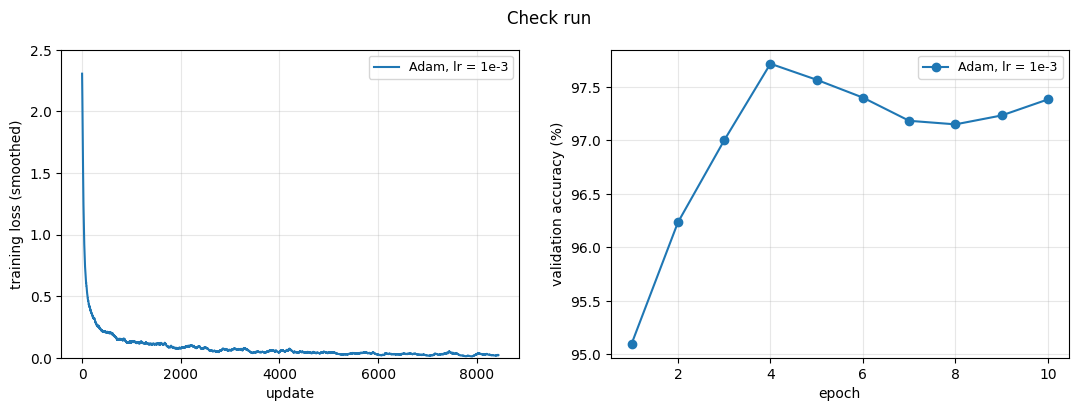

In [11]:
model = make_model(seed=0)
optimizer = optim.Adam(model.parameters(), lr=0.001)
hist = fit(model, optimizer, make_loader(batch_size=64, n_train=None), epochs=10)
plot_history({"Adam, lr = 1e-3": hist}, "Check run")

epoch  1 | lr 1.00e-01 | train loss 0.3062 | val loss 0.1591 | val acc 95.12% | 1.8 s
epoch  2 | lr 1.00e-01 | train loss 0.1166 | val loss 0.1089 | val acc 96.62% | 4.3 s
epoch  3 | lr 1.00e-01 | train loss 0.0816 | val loss 0.0936 | val acc 96.98% | 6.0 s
epoch  4 | lr 1.00e-01 | train loss 0.0601 | val loss 0.0949 | val acc 96.90% | 8.1 s
epoch  5 | lr 1.00e-01 | train loss 0.0467 | val loss 0.0859 | val acc 97.40% | 10.6 s
epoch  6 | lr 1.00e-01 | train loss 0.0363 | val loss 0.0913 | val acc 97.42% | 12.6 s
epoch  7 | lr 1.00e-01 | train loss 0.0274 | val loss 0.0785 | val acc 97.62% | 14.4 s
epoch  8 | lr 1.00e-01 | train loss 0.0213 | val loss 0.0918 | val acc 97.45% | 16.2 s
epoch  9 | lr 1.00e-01 | train loss 0.0162 | val loss 0.0809 | val acc 97.88% | 18.0 s
epoch 10 | lr 1.00e-01 | train loss 0.0119 | val loss 0.0825 | val acc 97.75% | 19.8 s


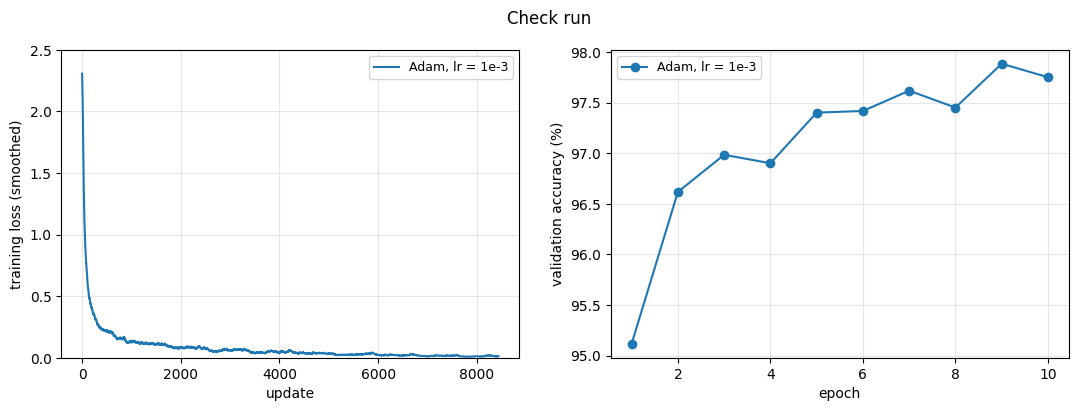

In [12]:
model = make_model(seed=0)
optimizer = optim.SGD(model.parameters(), lr=0.1)
hist = fit(model, optimizer, make_loader(batch_size=64, n_train=None), epochs=10)
plot_history({"Adam, lr = 1e-3": hist}, "Check run")

epoch  1 | lr 1.00e-01 | train loss 262.0604 | val loss 2.5642 | val acc 10.90% | 2.7 s
epoch  2 | lr 1.00e-01 | train loss 3.0876 | val loss 2.3171 | val acc 9.68% | 5.6 s
epoch  3 | lr 1.00e-01 | train loss 2.3175 | val loss 2.3057 | val acc 11.20% | 7.7 s
epoch  4 | lr 1.00e-01 | train loss 2.3100 | val loss 2.3119 | val acc 9.72% | 9.9 s
epoch  5 | lr 1.00e-01 | train loss 2.3108 | val loss 2.3120 | val acc 9.68% | 12.1 s
epoch  6 | lr 1.00e-01 | train loss 2.3099 | val loss 2.3058 | val acc 11.20% | 14.4 s
epoch  7 | lr 1.00e-01 | train loss 2.3101 | val loss 2.3116 | val acc 11.20% | 17.6 s
epoch  8 | lr 1.00e-01 | train loss 2.3106 | val loss 2.3057 | val acc 9.75% | 20.8 s
epoch  9 | lr 1.00e-01 | train loss 2.3104 | val loss 2.3043 | val acc 10.47% | 24.7 s
epoch 10 | lr 1.00e-01 | train loss 2.3102 | val loss 2.3081 | val acc 10.05% | 29.2 s


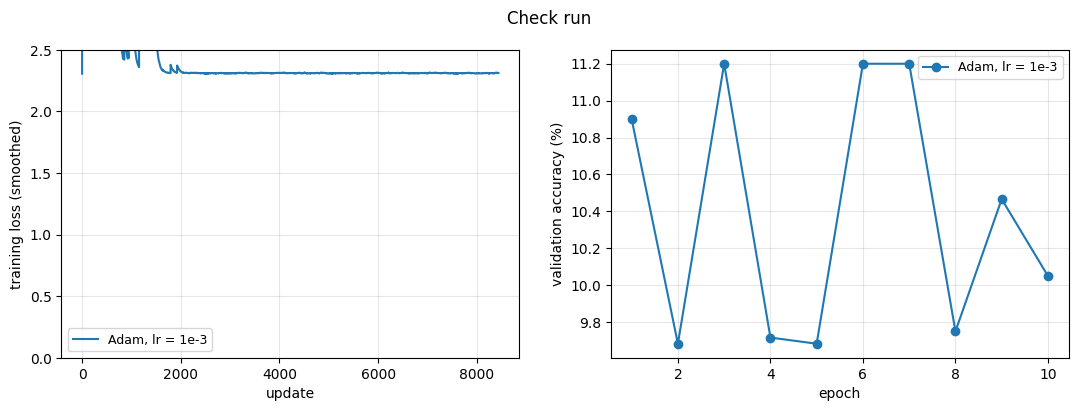

In [13]:
model = make_model(seed=0)
optimizer = optim.RMSprop(model.parameters(), lr=0.1)
hist = fit(model, optimizer, make_loader(batch_size=64, n_train=None), epochs=10)
plot_history({"Adam, lr = 1e-3": hist}, "Check run")

---
## ★ Exercises (to submit)

**Rules for all exercises**
- Train on the first **10,000** training examples (`make_loader(..., n_train=10_000)`) for **5 epochs**, unless the exercise says otherwise.
- Create every model with `make_model(seed=0)` (add `batch_norm=True` when asked), so that all runs start from the same weights.
- Use `fit`, `evaluate` and `plot_history` from Part 4. Choose everything on the **validation** set; use the test set only in Exercise 8.
- A run that diverges is a result too: report it.


### Exercise 1 · The learning rate of SGD
1. Train with `optim.SGD` (no momentum), batch size 64, for each $\alpha \in \{1, 0.3, 0.1, 0.03, 0.01, 0.001\}$.
2. Plot the six runs on one figure with `plot_history`.
3. Print the best validation accuracy of each run.


--- SGD (no momentum), lr = 1 ---
epoch  1 | lr 1.00e+00 | train loss 2402.3305 | val loss 19.0870 | val acc 10.90% | 0.6 s
epoch  2 | lr 1.00e+00 | train loss nan | val loss nan | val acc 9.72% | 0.8 s
diverged (loss is nan or inf): stopping

--- SGD (no momentum), lr = 0.3 ---
epoch  1 | lr 3.00e-01 | train loss 0.6940 | val loss 0.3263 | val acc 90.67% | 0.5 s
epoch  2 | lr 3.00e-01 | train loss 0.2314 | val loss 0.3524 | val acc 89.68% | 1.0 s
epoch  3 | lr 3.00e-01 | train loss 0.1474 | val loss 0.2704 | val acc 92.18% | 1.6 s
epoch  4 | lr 3.00e-01 | train loss 0.1072 | val loss 1.6728 | val acc 77.85% | 2.1 s
epoch  5 | lr 3.00e-01 | train loss 0.1070 | val loss 0.2353 | val acc 93.67% | 2.5 s

--- SGD (no momentum), lr = 0.1 ---
epoch  1 | lr 1.00e-01 | train loss 0.7062 | val loss 0.3833 | val acc 88.55% | 0.4 s
epoch  2 | lr 1.00e-01 | train loss 0.2839 | val loss 0.3740 | val acc 88.03% | 0.7 s
epoch  3 | lr 1.00e-01 | train loss 0.2034 | val loss 0.2901 | val acc 91.38% | 

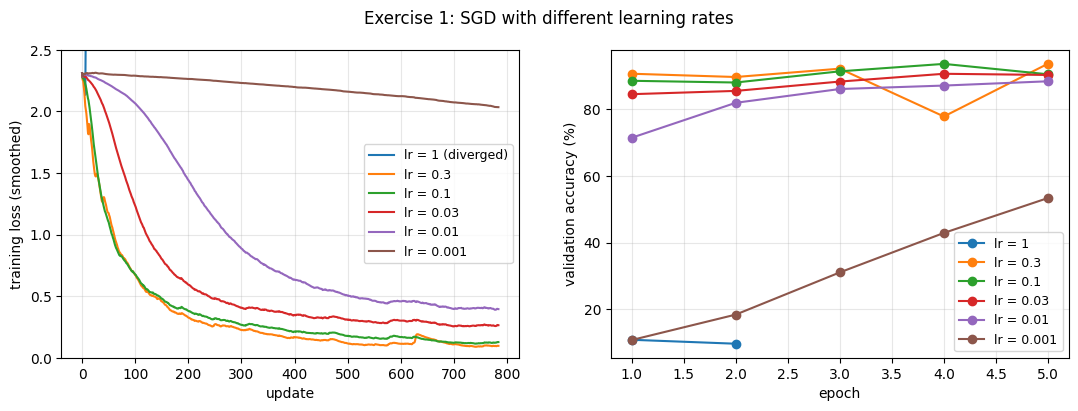

Best validation accuracy per learning rate:
  lr = 1       | best:  10.90% | final:   9.72% (diverged)
  lr = 0.3     | best:  93.67% | final:  93.67%
  lr = 0.1     | best:  93.62% | final:  90.50%
  lr = 0.03    | best:  90.65% | final:  90.30%
  lr = 0.01    | best:  88.40% | final:  88.40%
  lr = 0.001   | best:  53.40% | final:  53.40%


In [14]:
# Exercise 1
ex1_lrs = [1, 0.3, 0.1, 0.03, 0.01, 0.001]
ex1_hists = {}

for lr in ex1_lrs:
    print(f"\n--- SGD (no momentum), lr = {lr} ---")
    model = make_model(seed=0)
    optimizer = optim.SGD(model.parameters(), lr=lr)
    loader = make_loader(batch_size=64, n_train=10_000)
    ex1_hists[f"lr = {lr}"] = fit(model, optimizer, loader, epochs=5)

plot_history(ex1_hists, "Exercise 1: SGD with different learning rates")

print("Best validation accuracy per learning rate:")
for label, h in ex1_hists.items():
    best_acc = max(h["val_acc"])
    final_acc = h["val_acc"][-1]
    status = " (diverged)" if h["diverged"] else ""
    print(f"  {label:12s} | best: {best_acc:6.2f}% | final: {final_acc:6.2f}%{status}")



* **What the experiment demonstrates:** This experiment shows how the **Learning Rate** ($\alpha$) controls convergence speed, training stability, and **Validation Accuracy** when training an MLP with plain `SGD` (without Momentum) for 5 epochs on 10,000 MNIST examples (`batch_size=64`).
* **Actual results and observations:**
  * `lr = 1`: Highly unstable. Training loss stays above `2.0`, validation loss spikes to `8.1499` at epoch 3, and **Validation Accuracy** peaks at only `21.93%` (epoch 2) before dropping to `12.60%` by epoch 5.
  * `lr = 0.3`: Reaches the highest peak **Validation Accuracy** (**`93.67%`** at epoch 5) and gives the fastest initial drop in training loss, **but** suffers severe instability at epoch 4 where validation accuracy plunges from `92.18%` to `77.85%` (`val loss = 1.6728`) before recovering.
  * `lr = 0.1`: Converges quickly to `93.62%` at epoch 4 (`val loss = 0.2095`), then drops to `90.50%` at epoch 5 (`val loss = 0.3302`) due to late-stage oscillation.
  * `lr = 0.03`: Smooth training-loss curve and steady progress (`84.53% -> 90.65%` best at epoch 4, `90.27%` final).
  * `lr = 0.01`: Smooth, monotonic improvement (`71.47% -> 88.40%`), but still under-converged after 5 epochs.
  * `lr = 0.001`: Far too slow within 5 epochs (`train loss = 2.0486`, **Validation Accuracy** reaches only `53.40%`).
* **Best configuration (based on validation):** `lr = 0.3` achieved the highest single-epoch validation accuracy (`93.67%`), while `lr = 0.1` reached nearly the same peak (`93.62%`) with less extreme mid-training spikes, and `lr = 0.03` gave the smoothest stable curve above `90%` (`90.65%`).
* **Why this happens (ML concepts):** In **Gradient Descent** ($\theta \leftarrow \theta - \alpha \nabla J$), the **Learning Rate** scales every parameter update. When $\alpha$ is too small (`0.001`, `0.01`), steps are tiny and the optimizer makes slow progress in 5 epochs (**under-convergence**). When $\alpha$ is too large (`0.3`, `1`), steps overshoot the steep walls of narrow ravines in the loss surface, causing wild oscillations (`lr = 0.3` at epoch 4) or complete failure to settle (`lr = 1`). Even `lr = 0.1`–`0.3` needs Learning Rate decay to stay settled at the minimum.

###Khmer
* **គោលបំណងនៃការពិសោធន៍៖** ការពិសោធន៍នេះបង្ហាញពីឥទ្ធិពលរបស់ **Learning Rate** ($\alpha$) ទៅលើល្បឿននៃ **Convergence** ស្ថិរភាពក្នុងពេល train (**Training Stability**) និង **Validation Accuracy** នៅពេលប្រើ `SGD` ធម្មតា (គ្មាន Momentum) ចំនួន 5 epochs លើទិន្នន័យ 10,000 ឧទាហរណ៍ (`batch_size=64`)។
* **លទ្ធផលជាក់ស្តែងដែលសង្កេតឃើញ៖**
  * `lr = 1`៖ គ្មានស្ថិរភាពខ្លាំង។ Training Loss នៅខ្ពស់ជាង `2.0` រហូត ហើយ Validation Loss ហក់ឡើងដល់ `8.1499` នៅ epoch ទី 3 ចំណែក **Validation Accuracy** ឡើងដល់ត្រឹម `21.93%` (epoch 2) ហើយធ្លាក់ចុះមក `12.60%` នៅ epoch ទី 5។
  * `lr = 0.3`៖ ទទួលបាន **Validation Accuracy** ខ្ពស់ជាងគេ (**`93.67%`** នៅ epoch 5) និងទម្លាក់ Loss លឿនជាងគេនៅដំបូង **ប៉ុន្តែ** មានការរលាក់ខ្លាំង (instability) នៅ epoch ទី 4 ដែលធ្វើឱ្យ Accuracy ធ្លាក់ពី `92.18%` មក `77.85%` (`val loss = 1.6728`) មុននឹងឡើងវិញ។
  * `lr = 0.1`៖ រត់ទៅចំណុចល្អបានលឿន (`93.62%` នៅ epoch 4) ប៉ុន្តែធ្លាក់បន្តិចមក `90.50%` នៅ epoch 5 (`val loss` កើនពី `0.2095` ទៅ `0.3302`)។
  * `lr = 0.03`៖ ខ្សែ Loss ចុះយ៉ាងរលូន និង Accuracy កើនឡើងស្មើល្អ (`84.53% -> 90.65%` ល្អបំផុត, `90.27%` ចុងក្រោយ)។
  * `lr = 0.01`៖ មានស្ថិរភាពល្អ និងកើនឡើងជាលំដាប់ (`71.47% -> 88.40%`) ប៉ុន្តែនៅយឺត មិនទាន់ដល់ចំណុចល្អបំផុតក្នុង 5 epochs។
  * `lr = 0.001`៖ តូចពេក និងយឺតខ្លាំង ដោយនៅ epoch ទី 5 Training Loss នៅសល់ `2.0486` ហើយ Validation Accuracy បានត្រឹម `53.40%` ប៉ុណ្ណោះ។
* **ការជ្រើសរើសល្អបំផុតលើ Validation Set៖** `lr = 0.3` ឈានដល់ Accuracy ខ្ពស់បំផុត (`93.67%`) ខណៈ `lr = 0.1` បានជិតស្មើ (`93.62%`) ដោយមានការរលាក់តិចជាង។
* **ហេតុផលតាមទ្រឹស្តី ML៖** ក្នុងរូបមន្ត **Gradient Descent** ($\theta \leftarrow \theta - \alpha \nabla J$) តម្លៃ **Learning Rate** កំណត់ទំហំជំហាននៃការកែ weights។ បើ $\alpha$ តូចពេក (`0.001`, `0.01`) ជំហានតូចពេក ធ្វើឱ្យ Model រៀនយឺតក្នុង 5 epochs។ ផ្ទុយទៅវិញ បើ $\alpha$ ធំពេក (`0.3`, `1`) ជំហានលោតហួសចំណុចអប្បបរមា (overshoot) បង្កើតជាការយោលទៅមកខ្លាំង (oscillation) ឬមិនអាច converge បានឡើយ។

### Exercise 2 · Batch size: one example, mini-batches, the full set
1. Train with `optim.SGD`, $\alpha = 0.01$, for **3 epochs**, with batch sizes 1, 32, 256 and 10,000 (10,000 = batch gradient descent on this training set).
2. For each run, print the number of updates per epoch, the time per epoch and the best validation accuracy.
3. Plot the four runs.
4. Repeat steps 1–3 with $\alpha = 0.1$.

In [ ]:
# Exercise 2
ex2_batch_sizes = [1, 32, 256, 10_000]

for lr in [0.01, 0.1]:
    print(f"\n================ SGD, lr = {lr} ================")
    hists = {}
    summary_rows = []
    for bs in ex2_batch_sizes:
        print(f"\n--- batch_size = {bs}, lr = {lr} ---")
        model = make_model(seed=0)
        optimizer = optim.SGD(model.parameters(), lr=lr)
        loader = make_loader(batch_size=bs, n_train=10_000)
        h = fit(model, optimizer, loader, epochs=3)
        hists[f"batch = {bs}"] = h

        updates_per_epoch = len(loader)
        time_per_epoch = h["time"][-1] / len(h["time"])
        best_acc = max(h["val_acc"])
        status = " (diverged)" if h["diverged"] else ""
        summary_rows.append((bs, updates_per_epoch, time_per_epoch, best_acc, status))

    print(f"\nSummary (SGD, lr = {lr}, 3 epochs):")
    print(f"  {'batch_size':>10s} | {'updates/epoch':>13s} | {'time/epoch (s)':>14s} | {'best val acc':>14s}")
    for bs, upd, t_ep, acc, status in summary_rows:
        print(f"  {bs:10d} | {upd:13d} | {t_ep:14.2f} | {acc:11.2f}%{status}")

    plot_history(hists, f"Exercise 2: Batch size comparison (SGD, lr = {lr})")


================ SGD, lr = 0.01 ================

--- batch_size = 1, lr = 0.01 ---
epoch  1 | lr 1.00e-02 | train loss 0.4416 | val loss 0.4109 | val acc 89.62% | 8.2 s



* **What the experiment demonstrates:** This experiment compares **Stochastic Gradient Descent** (`batch_size = 1`), **Mini-batch SGD** (`batch_size = 32` and `256`), and **Batch Gradient Descent** (`batch_size = 10,000`) over 3 epochs on 10,000 examples at two learning rates ($\alpha = 0.01$ and $\alpha = 0.1$).
* **Actual results and observations:**
  * **At $\alpha = 0.01$:**
    * `batch_size = 1`: `10,000` updates/epoch, `3.83 s/epoch` (slowest), noisy step-loss curve, highest **Validation Accuracy** at **`93.57%`** (epoch 2; `93.20%` final).
    * `batch_size = 32`: `313` updates/epoch, `0.19 s/epoch` (~20× faster per epoch than `batch_size = 1`), smooth curve, `88.87%` best validation accuracy.
    * `batch_size = 256`: `40` updates/epoch, `0.07 s/epoch`, `64.63%` best validation accuracy.
    * `batch_size = 10,000`: `1` update/epoch (only 3 updates total), `0.11 s/epoch`, `9.80%` (remains near random guessing).
  * **At $\alpha = 0.1$:**
    * `batch_size = 1`: `10,000` updates/epoch, `1.30 s` before stopping — **diverged** (`NaN` loss in epoch 1, `9.72%`).
    * `batch_size = 32`: `313` updates/epoch, `0.22 s/epoch`, completely stable and reaches **`93.57%`** — matching `batch_size = 1` at `lr = 0.01` while running ~17× faster per epoch.
    * `batch_size = 256`: `40` updates/epoch, `0.10 s/epoch`, improves to `74.68%` (with a small dip to `67.50%` at epoch 2).
    * `batch_size = 10,000`: `1` update/epoch, `0.07 s/epoch`, reaches only `17.55%` after 3 updates.
* **Best configuration (based on validation):** `batch_size = 32` with $\alpha = 0.1$ achieved the top **Validation Accuracy** (`93.57%`) stably and in just `0.22 s/epoch`.
* **Why this happens (ML concepts):**
  * **Updates per epoch vs. vectorization:** Smaller batches perform far more gradient steps per epoch (`10,000` vs. `313` vs. `40` vs. `1`), driving faster learning per epoch. However, `batch_size = 1` executes 10,000 tiny Python loop steps per epoch without hardware vectorization, making it much slower in wall-clock time. Mini-batches (`32`, `256`) vectorize matrix multiplications across multiple examples at once.
  * **Gradient stability and Learning Rate:** Single-example gradients (`batch_size = 1`) have very high variance. At $\alpha = 0.1$, noisy gradient spikes push weights to overflow into `NaN` (**divergence**). Averaging gradients over 32 examples greatly reduces gradient noise, stabilizing $\alpha = 0.1$. Full-batch GD (`10,000`) has the cleanest gradient direction, but taking only 1 step per epoch (3 steps in 3 epochs) is far too few updates to learn.

###Khmer
* **គោលបំណងនៃការពិសោធន៍៖** ការពិសោធន៍នេះប្រៀបធៀប **Batch Size** ចំនួន 4 គឺ `1` (Stochastic GD), `32` និង `256` (Mini-batch SGD) និង `10,000` (Batch Gradient Descent) ក្នុងរយៈពេល 3 epochs ជាមួយ **Learning Rate** $\alpha = 0.01$ និង $\alpha = 0.1$។
* **លទ្ធផលជាក់ស្តែងដែលសង្កេតឃើញ៖**
  * **ពេលប្រើ $\alpha = 0.01$៖**
    * `batch_size = 1`៖ ធ្វើ `10,000` updates/epoch, ចំណាយពេលយូរជាងគេ (`3.83 s/epoch`), ខ្សែ Loss ញាក់ខ្លាំង ប៉ុន្តែបាន **Validation Accuracy** ខ្ពស់ជាងគេ (**`93.57%`** នៅ epoch 2) ព្រោះវាធ្វើ update ដល់ 30,000 ដងក្នុង 3 epochs។
    * `batch_size = 32`៖ ធ្វើ `313` updates/epoch, លឿនជាងមុន ~20 ដង (`0.19 s/epoch`), ខ្សែ Loss រលូនជាងមុន និងបាន `88.87%`។
    * `batch_size = 256`៖ ធ្វើ `40` updates/epoch (`0.07 s/epoch`) និងបាន `64.63%`។
    * `batch_size = 10,000`៖ ធ្វើត្រឹម `1` update/epoch (សរុប 3 updates) បានត្រឹម `9.80%` (ស្ទើរតែដូចការទាយព្រាវ)។
  * **ពេលប្រើ $\alpha = 0.1$៖**
    * `batch_size = 1`៖ **diverged** (Loss ក្លាយជា `NaN` តាំងពី epoch ទី 1, Accuracy `9.72%`)។
    * `batch_size = 32`៖ ដំណើរការមានស្ថិរភាពល្អ និងឈានដល់ **`93.57%`** ដោយចំណាយពេលត្រឹម `0.22 s/epoch` (លឿនជាង `batch_size=1` នៅ `lr=0.01` ប្រហែល 17 ដង)។
    * `batch_size = 256`៖ កើនដល់ `74.68%` (`0.10 s/epoch`)។
    * `batch_size = 10,000`៖ ទើបឡើងដល់ `17.55%` (`0.07 s/epoch`)។
* **ការជ្រើសរើសល្អបំផុតលើ Validation Set៖** Mini-batch `batch_size = 32` ជាមួយ $\alpha = 0.1$ ល្អបំផុតទាំង Accuracy (`93.57%`) ទាំងល្បឿន និងស្ថិរភាព។
* **ហេតុផលតាមទ្រឹស្តី ML៖**
  * **ចំនួន Updates និង Vectorization៖** Batch តូចផ្តល់ចំនួន updates ច្រើនក្នុង 1 epoch ប៉ុន្តែ `batch_size = 1` មិនអាចប្រើ vectorization របស់ CPU/GPU បានទេ ហើយខាតពេលលើ Python loop 10,000 ដងក្នុង 1 epoch។ ចំណែក Batch `32` ឬ `256` គណនាជា matrix ម្តងច្រើនទិន្នន័យ ទើបលឿនខ្លាំង។
  * **ស្ថិរភាពនៃ Gradient និង Learning Rate៖** Gradient ពីទិន្នន័យ 1 គ្រាប់ (`batch_size = 1`) មាន noise ខ្ពស់ខ្លាំង ដូច្នេះពេល $\alpha = 0.1$ វាធ្វើឱ្យ weights ផ្ទុះទៅជា `NaN` (divergence)។ ការគណនាមធ្យមលើ 32 ទិន្នន័យជួយកាត់បន្ថយ variance របស់ Gradient ធ្វើឱ្យអាចប្រើ $\alpha = 0.1$ បានដោយសុវត្ថិភាព។ រីឯ Full-batch (`10,000`) មាន Gradient ត្រឹមត្រូវបំផុត ប៉ុន្តែ 1 epoch កែបានតែ 1 ដង ទើបដើរយឺតខ្លាំងក្នុង 3 epochs។

### Exercise 3 · Momentum
1. With batch size 64 and $\alpha = 0.01$, train: `optim.SGD(p, lr)`, `optim.SGD(p, lr, momentum=0.9)` and `optim.SGD(p, lr, momentum=0.9, nesterov=True)`.
2. Train `optim.SGD(p, lr=0.001, momentum=0.9)` and compare it with plain SGD at $\alpha = 0.01$.
3. Train `optim.SGD(p, lr, momentum=0.99)` with $\alpha = 0.01$.
4. Plot all the runs on one figure.

In [ ]:
# Exercise 3
ex3_configs = [
    ("SGD, lr=0.01", {"lr": 0.01}),
    ("Momentum 0.9, lr=0.01", {"lr": 0.01, "momentum": 0.9}),
    ("Nesterov 0.9, lr=0.01", {"lr": 0.01, "momentum": 0.9, "nesterov": True}),
    ("Momentum 0.9, lr=0.001", {"lr": 0.001, "momentum": 0.9}),
    ("Momentum 0.99, lr=0.01", {"lr": 0.01, "momentum": 0.99}),
]

ex3_hists = {}
for label, opt_kwargs in ex3_configs:
    print(f"\n--- {label} ---")
    model = make_model(seed=0)
    optimizer = optim.SGD(model.parameters(), **opt_kwargs)
    loader = make_loader(batch_size=64, n_train=10_000)
    ex3_hists[label] = fit(model, optimizer, loader, epochs=5)

plot_history(ex3_hists, "Exercise 3: Momentum variants (batch_size = 64)")

print("Summary of validation accuracies:")
for label, h in ex3_hists.items():
    best_acc = max(h["val_acc"])
    final_acc = h["val_acc"][-1]
    status = " (diverged)" if h["diverged"] else ""
    print(f"  {label:24s} | best: {best_acc:6.2f}% | final: {final_acc:6.2f}%{status}")

sgd_001 = ex3_hists["SGD, lr=0.01"]
mom_0001 = ex3_hists["Momentum 0.9, lr=0.001"]
print(f"\nDirect comparison (effective step alpha / (1 - beta) = 0.001 / 0.1 = 0.01):")
print(f"  SGD (lr=0.01)            | best: {max(sgd_001['val_acc']):6.2f}% | final: {sgd_001['val_acc'][-1]:6.2f}%")
print(f"  Momentum 0.9 (lr=0.001)  | best: {max(mom_0001['val_acc']):6.2f}% | final: {mom_0001['val_acc'][-1]:6.2f}%")


* **What the experiment demonstrates:** This experiment examines **Momentum** and **Nesterov Momentum**, compares `SGD(lr=0.001, momentum=0.9)` against plain `SGD(lr=0.01)`, and shows what happens when `momentum` is set too high (`0.99`). All runs use `batch_size=64` for 5 epochs.
* **Actual results and observations:**
  * `SGD, lr=0.01` (plain SGD): Reaches `88.40%` best/final **Validation Accuracy** (`train loss` decreases from `1.9640` to `0.3938`).
  * `Momentum 0.9, lr=0.01`: Jumps to **`93.98%`** best/final (`+5.58` percentage points over plain SGD at the same $\alpha$), with epoch-1 `train loss = 0.8135` and `val acc = 89.23%`.
  * `Nesterov 0.9, lr=0.01`: Achieves `93.93%` best at epoch 4 (`93.58%` final), almost tied with classical momentum `0.9` and slightly lower epoch-1 `train loss` (`0.7820`).
  * `Momentum 0.9, lr=0.001` vs. plain `SGD, lr=0.01`: Produces nearly **identical** validation accuracy (`88.37%` vs. `88.40%`) and overlapping loss/accuracy curves from epoch 2 onward (`82.53% -> 85.87% -> 87.68% -> 88.37%` vs. `81.95% -> 86.08% -> 87.12% -> 88.40%`), lagging slightly only in epoch 1 (`68.02%` vs. `71.47%`).
  * `Momentum 0.99, lr=0.01`: Drops to `91.58%` best at epoch 4 (`91.35%` final) — noticeably worse and noisier than `momentum = 0.9`, with `train loss` rising slightly at epoch 5 (`0.2266 -> 0.2410`).
* **Best configuration (based on validation):** `SGD(lr=0.01, momentum=0.9)` (`93.98%`) and `Nesterov 0.9` (`93.93%`) perform best.
* **Why this happens (ML concepts):**
  * **Momentum & Nesterov:** Classical **Momentum** maintains an exponentially weighted velocity $v_t = \beta v_{t-1} + g_t$ and updates $\theta_t = \theta_{t-1} - \alpha v_t$. Opposite-sign gradients across steep ravine walls cancel out, while consistent gradients along shallow valleys accumulate speed—yielding a major jump from `88.40%` to `93.98%`. **Nesterov Momentum** computes the gradient at the lookahead position $\theta - \alpha \beta v$, helping anticipate turns slightly sooner.
  * **Effective step size (`0.001` with `0.9` vs. `0.01` plain SGD):** Because PyTorch's `optim.SGD` omits the $(1 - \beta)$ factor in $v_t = \beta v_{t-1} + g_t$, in steady state along a persistent direction $v_t \approx \frac{1}{1-\beta} g_t$, giving an effective Learning Rate of $\frac{\alpha}{1-\beta}$. For $\alpha = 0.001$ and $\beta = 0.9$, $\frac{0.001}{1 - 0.9} = 0.01$, matching plain SGD at $\alpha = 0.01$ after a ~10-step warm-up ($\frac{1}{1-0.9} = 10$).
  * **Too much momentum (`0.99`):** With $\beta = 0.99$, the steady-state multiplier becomes $\frac{1}{1-0.99} = 100\times$ (effective $\alpha \approx 1.0$) and velocity averages over ~100 past gradients, causing the optimizer to overshoot minima and turn too slowly.

###Khmer
* **គោលបំណងនៃការពិសោធន៍៖** ការពិសោធន៍នេះសិក្សាពី **Momentum** និង **Nesterov Momentum**, ប្រៀបធៀប `SGD(lr=0.001, momentum=0.9)` ជាមួយ `SGD(lr=0.01)` ធម្មតា និងពិនិត្យផលប៉ះពាល់នៃការដាក់ `momentum = 0.99` ខ្ពស់ពេក (ប្រើ `batch_size=64` រយៈពេល 5 epochs)។
* **លទ្ធផលជាក់ស្តែងដែលសង្កេតឃើញ៖**
  * `SGD, lr=0.01` ធម្មតា៖ បាន **Validation Accuracy** `88.40%` (`train loss` ចុះពី `1.9640` មក `0.3938`)។
  * `Momentum 0.9, lr=0.01`៖ កើនឡើងខ្លាំងដល់ **`93.98%`** (ខ្ពស់ជាង SGD ធម្មតា `+5.58%`) ដោយនៅ epoch ទី 1 បាន `89.23%` រួចទៅហើយ។
  * `Nesterov 0.9, lr=0.01`៖ បាន `93.93%` នៅ epoch 4 (`93.58%` ចុងក្រោយ) ដែលល្អប្រហាក់ប្រហែល Momentum ធម្មតា និងទម្លាក់ Training Loss នៅ epoch ទី 1 បានទាបជាងបន្តិច (`0.7820` ធៀបនឹង `0.8135`)។
  * `Momentum 0.9, lr=0.001` ធៀបនឹង `SGD, lr=0.01`៖ ខ្សែ Loss និង **Validation Accuracy** ជាន់គ្នាស្ទើរតែដូចគ្នាបេះបិទចាប់ពី epoch 2 តទៅ (`88.37%` ធៀបនឹង `88.40%`) ដោយយឺតជាងបន្តិចតែនៅ epoch ទី 1 ប៉ុណ្ណោះ (`68.02%` ធៀបនឹង `71.47%`)។
  * `Momentum 0.99, lr=0.01`៖ ធ្លាក់ចុះមកត្រឹម `91.58%` (`91.35%` ចុងក្រោយ) ហើយ Training Loss កើនវិញនៅ epoch ទី 5 (`0.2266 -> 0.2410`)។
* **ការជ្រើសរើសល្អបំផុតលើ Validation Set៖** `SGD(lr=0.01, momentum=0.9)` (`93.98%`) និង `Nesterov 0.9` (`93.93%`)។
* **ហេតុផលតាមទ្រឹស្តី ML៖**
  * **Momentum និង Nesterov៖** **Momentum** សន្សំល្បឿនពី Gradient ចាស់ៗ ($v_t = \beta v_{t-1} + g_t$) ដើម្បីលុបបំបាត់ការយោលទៅមកតាមទិសចោត និងបង្កើនល្បឿនតាមជ្រលងរាប ទើបធ្វើឱ្យ Accuracy លោតពី `88.40%` ទៅ `93.98%`។ ចំណែក **Nesterov Momentum** គណនា Gradient នៅទីតាំងខាងមុខបន្តិច ($\theta - \alpha \beta v$) ដើម្បីបន្ថយល្បឿនទាន់ពេលមុនពេលហួសគោលដៅ។
  * **ហេតុអ្វី `lr=0.001, mom=0.9` ស្មើ `SGD lr=0.01`៖** ក្នុង PyTorch `optim.SGD` គ្មានមេគុណ $(1 - \beta)$ មុខ $g_t$ ទេ ដូច្នេះក្នុងស្ថានភាពថេរ $v_t \approx \frac{1}{1-\beta} g_t$ ដែលផ្តល់ Learning Rate ប្រសិទ្ធផល $\frac{\alpha}{1-\beta} = \frac{0.001}{1-0.9} = 0.01$ ដូចគ្នានឹង SGD ធម្មតា $\alpha=0.01$ ដែរ (គ្រាន់តែនៅ epoch ទី 1 វាត្រូវការ ~10 ជំហានដើម្បីសន្សំល្បឿនដំបូង)។
  * **Momentum ខ្ពស់ពេក (`0.99`)៖** វាគុណជំហានដល់ $\frac{1}{1-0.99} = 100$ ដង (effective $\alpha \approx 1.0$) និងចងចាំ Gradient ចាស់ៗដល់ ~100 ជំហាន ធ្វើឱ្យរត់ជ្រុលហួសចំណុចអប្បបរមា និងបត់បែនយឺត។

### Exercise 4 · Optimizers and their learning rates
1. For each optimizer below, train with $\alpha \in \{10^{-1}, 10^{-2}, 10^{-3}, 10^{-4}\}$, batch size 64:
   `optim.SGD`, `optim.SGD(momentum=0.9)`, `optim.Adagrad`, `optim.RMSprop`, `optim.Adam`, `optim.AdamW`.
2. Show a table of the best validation accuracy: one row per optimizer, one column per learning rate.
3. Plot the best run of each optimizer on one figure.

In [ ]:
# Exercise 4
ex4_lrs = [1e-1, 1e-2, 1e-3, 1e-4]
ex4_optimizers = {
    "SGD": lambda p, lr: optim.SGD(p, lr=lr),
    "SGD (mom=0.9)": lambda p, lr: optim.SGD(p, lr=lr, momentum=0.9),
    "Adagrad": lambda p, lr: optim.Adagrad(p, lr=lr),
    "RMSprop": lambda p, lr: optim.RMSprop(p, lr=lr),
    "Adam": lambda p, lr: optim.Adam(p, lr=lr),
    "AdamW": lambda p, lr: optim.AdamW(p, lr=lr),
}

ex4_results = {}
for opt_name, opt_fn in ex4_optimizers.items():
    ex4_results[opt_name] = {}
    for lr in ex4_lrs:
        model = make_model(seed=0)
        optimizer = opt_fn(model.parameters(), lr)
        loader = make_loader(batch_size=64, n_train=10_000)
        h = fit(model, optimizer, loader, epochs=5, verbose=False)
        ex4_results[opt_name][lr] = h
        status = " (diverged)" if h["diverged"] else ""
        print(f"{opt_name:15s} | lr={lr:<7g} | best val acc={max(h['val_acc']):6.2f}% | final={h['val_acc'][-1]:6.2f}%{status}")

print("\nBest validation accuracy (%) table (div = diverged):")
header = f"{'Optimizer':16s} | " + " | ".join(f"{f'lr={lr:g}':>13s}" for lr in ex4_lrs)
print(header)
print("-" * len(header))

ex4_best_runs = {}
for opt_name in ex4_optimizers:
    cells = []
    for lr in ex4_lrs:
        h = ex4_results[opt_name][lr]
        best_acc = max(h["val_acc"])
        cell = f"{best_acc:6.2f}% (div)" if h["diverged"] else f"{best_acc:12.2f}%"
        cells.append(f"{cell:>13s}")
    print(f"{opt_name:16s} | " + " | ".join(cells))

    non_div = [(lr, max(ex4_results[opt_name][lr]["val_acc"])) for lr in ex4_lrs if not ex4_results[opt_name][lr]["diverged"]]
    best_lr = max(non_div, key=lambda x: x[1])[0] if non_div else max(ex4_lrs, key=lambda lr: max(ex4_results[opt_name][lr]["val_acc"]))
    ex4_best_runs[f"{opt_name} (lr={best_lr:g})"] = ex4_results[opt_name][best_lr]

plot_history(ex4_best_runs, "Exercise 4: Best run of each optimizer")


* **What the experiment demonstrates:** This experiment compares six optimizers—`SGD`, `SGD (momentum=0.9)`, `Adagrad`, `RMSprop`, `Adam`, and `AdamW`—across four learning rates ($\alpha \in \{10^{-1}, 10^{-2}, 10^{-3}, 10^{-4}\}$, `batch_size=64`, 5 epochs), showing how different optimization algorithms require different **Learning Rate** scales.
* **Actual results and observations:**
  * `SGD`: Best at `lr = 0.1` (`93.62%` peak, dipping to `90.50%` at epoch 5); drops sharply at smaller rates (`88.40%` at `0.01`, `53.40%` at `0.001`, `9.88%` at `0.0001`).
  * `SGD (mom=0.9)`: Best at `lr = 0.01` (`93.98%`), `93.20%` at `0.1`, `88.37%` at `0.001`, and `52.55%` at `0.0001`.
  * `Adagrad`: Best at `lr = 0.01` (`93.93%` peak, `93.45%` final), `91.77%` at `0.1`, `89.15%` at `0.001`, `67.98%` at `0.0001`.
  * `RMSprop`: Best at **`lr = 0.001`** (**`94.18%`** peak, `93.67%` final), `89.92%` at `0.0001`, `87.77%` at `0.01`, and collapses at `0.1` (`21.97%` peak, `12.15%` final).
  * `Adam`: Best at **`lr = 0.001`** (**`94.17%`** peak and final), `92.43%` at `0.01`, `90.03%` at `0.0001`, and unstable at `0.1` (`37.20%` peak, `25.87%` final).
  * `AdamW`: Best at **`lr = 0.001`** (**`94.02%`** peak and final), `92.95%` at `0.01`, `90.05%` at `0.0001`, and unstable at `0.1` (`26.77%` peak, `10.93%` final).
  * In the comparison plot of each optimizer's best run, `RMSprop (1e-3)`, `Adam (1e-3)`, and `AdamW (1e-3)` descend fastest in early updates, while `Adam (1e-3)` and `AdamW (1e-3)` show the smoothest monotonic **Validation Accuracy** growth through epoch 5.
* **Best configuration (based on validation):** `RMSprop (lr=0.001)` (`94.18%`) and `Adam (lr=0.001)` (`94.17%`) tie at the top, with `Adam` being the smoothest (`94.17%` at epoch 5 without late dip).
* **Why this happens (ML concepts):**
  * Plain `SGD` takes steps directly proportional to the raw **Gradient** ($\alpha g_t$), so it needs a relatively large $\alpha$ (`0.1`) to move quickly, while `SGD + Momentum` amplifies effective steps and shifts the optimal $\alpha$ down to `0.01`.
  * `Adagrad` divides each parameter's update by the square root of all past squared gradients ($\sqrt{\sum g^2} + \varepsilon$). This adapts per-coordinate step sizes, allowing `0.01` to work well early, though monotonic accumulation slows progress over longer training.
  * Adaptive methods with exponential moving averages (`RMSprop`, `Adam`, `AdamW`) normalize each coordinate by $\sqrt{S_t} + \varepsilon$, so update magnitudes are roughly $\mathcal{O}(\alpha)$ regardless of raw gradient size. Therefore, $\alpha = 0.1$ causes violent overshooting (`21.97%`–`37.20%`), whereas $\alpha = 10^{-3}$ works very well (and even `10^{-4}` reaches ~`90%`). `Adam` and `AdamW` combine this adaptive scaling with bias-corrected Momentum ($\beta_1 = 0.9$), explaining their smooth convergence (`AdamW` adds decoupled weight decay, behaving similarly to `Adam` over 5 epochs).

###Khmer
* **គោលបំណងនៃការពិសោធន៍៖** ការពិសោធន៍នេះប្រៀបធៀប **Optimizer** ចំនួន 6 (`SGD`, `SGD + Momentum`, `Adagrad`, `RMSprop`, `Adam`, `AdamW`) ជាមួយ **Learning Rate** 4 តម្លៃ ($10^{-1}, 10^{-2}, 10^{-3}, 10^{-4}$) លើ `batch_size=64` ចំនួន 5 epochs។
* **លទ្ធផលជាក់ស្តែងដែលសង្កេតឃើញ៖**
  * `SGD` ធម្មតា៖ ល្អបំផុតនៅ `lr = 0.1` (`93.62%` ប៉ុន្តែធ្លាក់មក `90.50%` នៅ epoch 5) ហើយធ្លាក់ចុះខ្លាំងពេល `lr` តូច (`9.88%` នៅ `1e-4`)។
  * `SGD (mom=0.9)`៖ ល្អបំផុតនៅ `lr = 0.01` (`93.98%`)។
  * `Adagrad`៖ ល្អបំផុតនៅ `lr = 0.01` (`93.93%` ចំណុចខ្ពស់បំផុត, `93.45%` ចុងក្រោយ)។
  * `RMSprop`៖ ល្អបំផុតនៅ **`lr = 0.001`** (**`94.18%`**, `93.67%` ចុងក្រោយ) ប៉ុន្តែគ្មានស្ថិរភាពខ្លាំងនៅ `lr = 0.1` (`21.97%` -> `12.15%`)។
  * `Adam`៖ ល្អបំផុតនៅ **`lr = 0.001`** (**`94.17%`** កើនឡើងរលូនដល់ epoch 5) និងខូចនៅ `lr = 0.1` (`37.20%`)។
  * `AdamW`៖ ល្អបំផុតនៅ **`lr = 0.001`** (**`94.02%`** កើនឡើងរលូនដល់ epoch 5) និងខូចនៅ `lr = 0.1` (`26.77%`)។
  * នៅលើក្រាហ្វ Run ល្អបំផុតរបស់ Optimizer នីមួយៗ `RMSprop`, `Adam` និង `AdamW` នៅ `1e-3` ទម្លាក់ Loss លឿនជាងគេ ហើយ `Adam` និង `AdamW` មានខ្សែ **Validation Accuracy** រលូនជាងគេ។
* **ការជ្រើសរើសល្អបំផុតលើ Validation Set៖** `RMSprop (lr=0.001)` (`94.18%`) និង `Adam (lr=0.001)` (`94.17%`) ទទួលបានលទ្ធផលខ្ពស់បំផុត ដោយ `Adam` រលូនជាងគេនៅ epoch ទី 5។
* **ហេតុផលតាមទ្រឹស្តី ML៖**
  * `SGD` ប្រើទំហំ **Gradient** ផ្ទាល់ ដូច្នេះត្រូវការ `lr` ធំ (`0.1`), ឯ `SGD + Momentum` គុណល្បឿនបន្ថែម ទើប `lr` ល្អបំផុតប្តូរមក `0.01`។
  * `Adagrad` ចែក Gradient នឹងឫសការ៉េនៃផលបូកការ៉េ Gradient ចាស់ៗទាំងអស់ ដែលជួយប្តូរជំហានតាមទិសនីមួយៗ ប៉ុន្តែយូរទៅជំហានកាន់តែរួមតូច។
  * Adaptive Optimizer (`RMSprop`, `Adam`, `AdamW`) ចែក Gradient នឹងមធ្យមរត់ $\sqrt{S_t} + \varepsilon$ ធ្វើឱ្យជំហានពិតប្រាកដនៃ weight នីមួយៗមានទំហំប្រហែល $\alpha$។ ហេតុនេះ `lr = 0.1` ធំពេកធ្វើឱ្យលោតហួសគោលដៅ ប៉ុន្តែ `lr = 1e-3` ដំណើរការល្អបំផុត។ `Adam` និង `AdamW` បញ្ចូលទាំង Momentum ($\beta_1$) និង RMSprop ($\beta_2$) ព្រមទាំង Bias Correction ទើបរៀនបានលឿន និងរលូន។

### Exercise 5 · Learning rate schedules
1. With `optim.SGD(p, lr=0.05, momentum=0.9)` and batch size 64, train for **10 epochs** with:
   - a constant learning rate;
   - `optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.3)`;
   - `optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.7)`;
   - `optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)`;
   - `optim.lr_scheduler.StepLR(optimizer, step_size=1, gamma=0.1)` (decays too early).
2. Plot the learning rate of each run per epoch (from `history["lr"]`), with a log scale on the y-axis.
3. Plot the five runs with `plot_history(..., ylim=(0, 0.8))`.

In [ ]:
# Exercise 5
ex5_sched_configs = [
    ("Constant lr=0.05", None),
    ("StepLR (step=3, gamma=0.3)", lambda opt: optim.lr_scheduler.StepLR(opt, step_size=3, gamma=0.3)),
    ("ExponentialLR (gamma=0.7)", lambda opt: optim.lr_scheduler.ExponentialLR(opt, gamma=0.7)),
    ("CosineAnnealingLR (T_max=10)", lambda opt: optim.lr_scheduler.CosineAnnealingLR(opt, T_max=10)),
    ("StepLR (step=1, gamma=0.1)", lambda opt: optim.lr_scheduler.StepLR(opt, step_size=1, gamma=0.1)),
]

ex5_hists = {}
for label, sched_fn in ex5_sched_configs:
    print(f"\n--- {label} ---")
    model = make_model(seed=0)
    optimizer = optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
    scheduler = sched_fn(optimizer) if sched_fn is not None else None
    loader = make_loader(batch_size=64, n_train=10_000)
    ex5_hists[label] = fit(model, optimizer, loader, epochs=10, scheduler=scheduler)

plt.figure(figsize=(7, 4))
for label, h in ex5_hists.items():
    plt.plot(range(1, len(h["lr"]) + 1), h["lr"], "o-", label=label)
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("learning rate (log scale)")
plt.title("Exercise 5: Learning rate per epoch")
plt.grid(alpha=0.3)
plt.legend(fontsize=9)
plt.show()

plot_history(ex5_hists, "Exercise 5: Learning rate schedules (SGD, lr=0.05, mom=0.9)", ylim=(0, 0.8))

print("Summary of validation accuracies (10 epochs):")
for label, h in ex5_hists.items():
    print(f"  {label:30s} | best: {max(h['val_acc']):6.2f}% | final: {h['val_acc'][-1]:6.2f}%")


* **What the experiment demonstrates:** This experiment shows how **Learning Rate Schedules** adjust $\alpha$ over 10 epochs (starting at `lr = 0.05` with `SGD(momentum=0.9)` and `batch_size=64`), comparing a fixed rate against `StepLR`, `ExponentialLR`, `CosineAnnealingLR`, and overly early decay.
* **Actual results and observations:**
  * `Constant lr=0.05`: Peaks at `95.18%` (epoch 8) and ends at `94.72%`, with noticeable epoch-to-epoch fluctuations (`94.05% -> 93.53% -> 95.00% -> 94.02% -> 95.18% -> 94.72%`) and higher final training loss (`0.0463`).
  * `StepLR (step_size=3, gamma=0.3)`: Jumps sharply from `93.53%` (epoch 3) to `95.33%` right after $\alpha$ drops from `0.05` to `1.50e-2` at epoch 4, reaching `95.75%` best (`95.70%` final).
  * `ExponentialLR (gamma=0.7)`: Decays smoothly each epoch (`5.00e-2` down to `2.02e-3`), achieving `95.63%` best (`95.60%` final).
  * `CosineAnnealingLR (T_max=10)`: Achieves the highest **Validation Accuracy** (**`96.08%`** at epoch 8, `96.03%` final) and lowest training loss (`0.0029` at epoch 10).
  * `StepLR (step_size=1, gamma=0.1)` (early decay): Drops linearly on the log-scale plot from `5.00e-2` down to `5.00e-11`, causing training to freeze completely by epoch 4 (`train loss = 0.1166`, **Validation Accuracy** stuck at `93.70%` from epoch 3 through epoch 10).
* **Best configuration (based on validation):** `CosineAnnealingLR (T_max=10)` achieved the best **Validation Accuracy** (`96.08%`).
* **Why this happens (ML concepts):**
  * With a **Constant Learning Rate** (`0.05`), mini-batch gradient noise remains large late in training, so parameters keep bouncing around the minimum (`94.72%` final).
  * **Early decay** (`StepLR(step_size=1, gamma=0.1)`) shrinks $\alpha$ by $10\times$ every epoch, starving optimization before the network can reach a low-loss basin (`93.70%` ceiling).
  * Effective **Learning Rate Schedules** balance fast exploration early with fine settling later. `StepLR(3, 0.3)` drops in staircases, `ExponentialLR(0.7)` decays by a fixed factor each epoch, and `CosineAnnealingLR` works best here because it decays gently at first (`0.05 -> 0.0327` over epochs 1–5) so the optimizer still crosses flat/ravine regions quickly, then anneals down toward `1.22e-3` in epochs 6–10 to settle tightly into the minimum.

###Khmer
* **គោលបំណងនៃការពិសោធន៍៖** ការពិសោធន៍នេះបង្ហាញពីការបន្ថយ **Learning Rate** តាម Epoch ដោយប្រើ `SGD(lr=0.05, momentum=0.9)` រយៈពេល 10 epochs (`batch_size=64`) ដើម្បីប្រៀបធៀប Constant Learning Rate ជាមួយ Scheduler 4 ប្រភេទ។
* **លទ្ធផលជាក់ស្តែងដែលសង្កេតឃើញ៖**
  * `Constant lr=0.05`៖ ឡើងដល់ `95.18%` (epoch 8) ហើយចុះមក `94.72%` ដោយខ្សែ Accuracy ឡើងចុះមិនស្ងប់ និង Training Loss នៅសល់ `0.0463`។
  * `StepLR (step=3, gamma=0.3)`៖ ពេល `lr` បន្ថយពី `0.05` មក `1.50e-2` នៅ epoch 4 Accuracy លោតភ្លាមពី `93.53%` ទៅ `95.33%` និងឈានដល់ `95.75%` (`95.70%` ចុងក្រោយ)។
  * `ExponentialLR (gamma=0.7)`៖ បន្ថយ `lr` រលូនរៀងរាល់ epoch (ពី `5.00e-2` ដល់ `2.02e-3`) និងបាន `95.63%` (`95.60%` ចុងក្រោយ)។
  * `CosineAnnealingLR (T_max=10)`៖ ទទួលបាន **Validation Accuracy** ខ្ពស់ជាងគេ (**`96.08%`** នៅ epoch 8, `96.03%` ចុងក្រោយ) និង Training Loss ទាបបំផុត (`0.0029`)។
  * `StepLR (step=1, gamma=0.1)` (បន្ថយលឿនពេក)៖ នៅលើក្រាហ្វ log scale តម្លៃ `lr` ធ្លាក់ដល់ `5.00e-11` ធ្វើឱ្យ Model ឈប់រៀនទាំងស្រុងចាប់ពី epoch ទី 4 (`train loss = 0.1166`, Accuracy ជាប់គាំងនៅ `93.70%`)។
* **ការជ្រើសរើសល្អបំផុតលើ Validation Set៖** `CosineAnnealingLR(T_max=10)` ល្អបំផុត (`96.08%`)។
* **ហេតុផលតាមទ្រឹស្តី ML៖**
  * ការប្រើ **Constant Learning Rate** ធំរហូតធ្វើឱ្យទំហំជំហាននៅចុងក្រោយធំពេក មិនអាចចុះដល់បាតជ្រលងនៃ Loss បានទេ (នៅរលាក់ជុំវិញចំណុចអប្បបរមា)។
  * ការបន្ថយ **Learning Rate** លឿនពេក (**early decay**) ធ្វើឱ្យ $\alpha$ ក្លាយជាសូន្យសឹងតែទាំងស្រុងមុនពេល Model រៀនចប់។
  * Scheduler ល្អត្រូវទុក `lr` ធំល្មមនៅដើមទីដើម្បីរៀនលឿន ហើយបន្ថយបន្តិចម្តងៗនៅចុងទីដើម្បីចូលបាតជ្រលងឱ្យស្ងប់។ `CosineAnnealingLR` ឈ្នះគេព្រោះវារក្សា `lr` ខ្ពស់ក្នុង 5 epochs ដំបូង (`0.05 -> 0.0327`) រួចទើបបន្ថយរលូនដល់ `1.22e-3` នៅ epoch ទី 10។

### Exercise 6 · Batch normalization
1. For $\alpha \in \{1, 10^{-1}, 10^{-2}, 10^{-3}\}$, train `optim.SGD(p, lr, momentum=0.9)` with batch size 64, once **without** and once **with** batch norm (`make_model(seed=0, batch_norm=True)`).
2. Show a table of the best validation accuracy: rows = learning rates, columns = without / with batch norm.
3. Plot the eight runs.
4. Take your batch-norm model trained with $\alpha = 10^{-2}$. Evaluate it on the validation set in `model.eval()` mode (as `evaluate` does) and in `model.train()` mode with mini-batches of 8 examples, and compare the two accuracies.

In [ ]:
# Exercise 6
ex6_lrs = [1, 1e-1, 1e-2, 1e-3]
ex6_results = {False: {}, True: {}}
ex6_hists = {}
bn_model_1e2 = None

for bn in [False, True]:
    bn_label = "BN" if bn else "no BN"
    for lr in ex6_lrs:
        print(f"\n--- {bn_label}, SGD (mom=0.9), lr = {lr} ---")
        model = make_model(seed=0, batch_norm=bn)
        optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
        loader = make_loader(batch_size=64, n_train=10_000)
        h = fit(model, optimizer, loader, epochs=5)
        ex6_results[bn][lr] = h
        ex6_hists[f"{bn_label}, lr={lr:g}"] = h
        if bn and lr == 1e-2:
            bn_model_1e2 = model

print("\nBest validation accuracy (%) table:")
print(f"{'lr':>8s} | {'without BN':>14s} | {'with BN':>14s}")
print("-" * 42)
for lr in ex6_lrs:
    row_vals = []
    for bn in [False, True]:
        h = ex6_results[bn][lr]
        acc = max(h["val_acc"])
        s = f"{acc:6.2f}% (div)" if h["diverged"] else f"{acc:13.2f}%"
        row_vals.append(f"{s:>14s}")
    print(f"{lr:8g} | {row_vals[0]} | {row_vals[1]}")

plot_history(ex6_hists, "Exercise 6: Effect of Batch Normalization")

# Step 4: eval() mode vs train() mode with mini-batches of 8 examples
import copy
eval_loss, eval_acc = evaluate(bn_model_1e2, X_val, y_val)

# Preserve training running stats before running a forward pass in train() mode
bn_state = copy.deepcopy(bn_model_1e2.state_dict())
bn_model_1e2.train()
loss_fn_sum = nn.CrossEntropyLoss(reduction="sum")
total_loss, correct = 0.0, 0
with torch.no_grad():
    for i in range(0, len(X_val), 8):
        xb = X_val[i:i + 8].to(device)
        yb = y_val[i:i + 8].to(device)
        logits = bn_model_1e2(xb)
        total_loss += loss_fn_sum(logits, yb).item()
        correct += (logits.argmax(dim=1) == yb).sum().item()
train8_loss = total_loss / len(X_val)
train8_acc = 100 * correct / len(X_val)
bn_model_1e2.load_state_dict(bn_state)
bn_model_1e2.eval()

print("\nValidation comparison for batch-norm model trained with lr = 1e-2:")
print(f"  model.eval() mode (running stats)        : loss = {eval_loss:.4f} | acc = {eval_acc:.2f}%")
print(f"  model.train() mode (mini-batches of 8)   : loss = {train8_loss:.4f} | acc = {train8_acc:.2f}%")
print(f"  Difference (eval - train with bs=8)      : {eval_acc - train8_acc:+.2f} percentage points")


* **What the experiment demonstrates:** This experiment evaluates **Batch Normalization** (`nn.BatchNorm1d` before ReLU) across $\alpha \in \{1, 10^{-1}, 10^{-2}, 10^{-3}\}$ using `SGD(momentum=0.9)` (`batch_size=64`, 5 epochs), and contrasts `model.eval()` with `model.train()` on small batches (`batch_size=8`) during validation.
* **Actual results and observations:**
  * **Without vs. With Batch Normalization:**
    * `lr = 1`: Without BN **diverged** to `NaN` in epoch 2 (`9.72% (div)`), whereas with BN it trained stably to `90.57%` (`89.53%` final).
    * `lr = 0.1`: `93.20%` (without BN) $\rightarrow$ `95.37%` (with BN, `+2.17` points).
    * `lr = 0.01`: `93.98%` (without BN) $\rightarrow$ **`95.38%`** (with BN, `+1.40` points).
    * `lr = 0.001`: `88.37%` (without BN) $\rightarrow$ `92.75%` (with BN, `+4.38` points).
  * **`model.eval()` vs. `model.train()` on the `lr = 0.01` BN model:**
    * `model.eval()` (uses training running statistics): `val loss = 0.1576`, **Validation Accuracy** = **`95.38%`**.
    * `model.train()` with mini-batches of 8 examples: `val loss = 0.4759`, **Validation Accuracy** = **`85.28%`** (`-10.10` percentage points lower).
* **Best configuration (based on validation):** `with BN` at `lr = 0.01` (`95.38%`) and `lr = 0.1` (`95.37%`), evaluated in `model.eval()` mode.
* **Why this happens (ML concepts):**
  * **Batch Normalization and stability:** `nn.BatchNorm1d` normalizes each hidden layer's pre-activations $Z^{[l]}$ per mini-batch to zero mean and unit variance before learned scale $\gamma$ and shift $\beta$. This reduces internal covariate shift, prevents activations and gradients from exploding at extreme learning rates (allowing `lr = 1` to converge instead of blowing up to `NaN`), smooths the optimization landscape, and boosts **Validation Accuracy** across every learning rate.
  * **`model.train()` vs. `model.eval()`:** During training (`model.train()`), BatchNorm computes $\mu$ and $\sigma^2$ from the **current mini-batch** and updates its `running_mean` and `running_var`. During evaluation (`model.eval()`), it freezes and uses those accumulated global running statistics. Evaluating in `model.train()` with only 8 examples across 10 classes gives very noisy batch $\mu$ and $\sigma^2$ estimates, distorting normalized activations and dropping accuracy by `10.10` percentage points.

###Khmer
* **គោលបំណងនៃការពិសោធន៍៖** ការពិសោធន៍នេះសិក្សាពីឥទ្ធិពលរបស់ **Batch Normalization** ទៅលើស្ថិរភាព និង **Validation Accuracy** លើ Learning Rate ទាំង 4 (`1, 0.1, 0.01, 0.001`) ព្រមទាំងប្រៀបធៀបរបៀប `model.eval()` និង `model.train()` ពេលធ្វើ evaluation។
* **លទ្ធផលជាក់ស្តែងដែលសង្កេតឃើញ៖**
  * **ប្រៀបធៀប Model គ្មាន BN និងមាន BN៖**
    * `lr = 1`៖ គ្មាន BN បាន **diverged** (ក្លាយជា `NaN` នៅ epoch 2, `9.72%`) ចំណែកមាន BN អាច train បានដោយស្ថិរភាពដល់ `90.57%`។
    * `lr = 0.1`៖ ឡើងពី `93.20%` (គ្មាន BN) ទៅ `95.37%` (មាន BN)។
    * `lr = 0.01`៖ ឡើងពី `93.98%` (គ្មាន BN) ទៅ **`95.38%`** (មាន BN)។
    * `lr = 0.001`៖ ឡើងពី `88.37%` (គ្មាន BN) ទៅ `92.75%` (មាន BN, កើន `+4.38%`)។
  * **ប្រៀបធៀប `model.eval()` និង `model.train()` (`batch_size=8`) លើ Model BN (`lr=0.01`)៖**
    * `model.eval()`៖ `val loss = 0.1576`, **Validation Accuracy** = **`95.38%`**។
    * `model.train()` ជាមួយ 8 ឧទាហរណ៍ក្នុង 1 batch៖ `val loss = 0.4759`, Accuracy ធ្លាក់មក **`85.28%`** (ធ្លាក់ចុះ `-10.10%`)។
* **ការជ្រើសរើសល្អបំផុតលើ Validation Set៖** Model ដែលមាន **Batch Normalization** ជាមួយ `lr = 0.01` (`95.38%`) ឬ `lr = 0.1` (`95.37%`) និងប្រើ `model.eval()` ពេលវាស់លទ្ធផល។
* **ហេតុផលតាមទ្រឹស្តី ML៖**
  * **ហេតុអ្វី Batch Normalization ជួយឱ្យមានស្ថិរភាព៖** វាធ្វើ normalize តម្លៃ pre-activation $Z^{[l]}$ ក្នុង layer នីមួយៗឱ្យមានមធ្យម `0` និង variance `1` រាល់ mini-batch (មុនពេលគុណ $\gamma$ និងបូក $\beta$)។ នេះជួយកាត់បន្ថយការប្រែប្រួល distribution ខាងក្នុង (Internal Covariate Shift), ទប់ស្កាត់ Gradient/Weight កុំឱ្យផ្ទុះនៅ `lr = 1` និងធ្វើឱ្យផ្ទៃ Loss រលូនងាយរត់ចុះ។
  * **ភាពខុសគ្នារវាង `model.train()` និង `model.eval()`៖** នៅក្នុង `model.train()` BatchNorm គណនា mean និង variance ចេញពី **mini-batch បច្ចុប្បន្ន** (ទើបពេល `batch_size=8` តម្លៃស្ថិតិទាំងនេះមាន noise ខ្លាំង ធ្វើឱ្យ Accuracy ធ្លាក់ `10.10%`)។ ចំណែកក្នុង `model.eval()` វាប្រើ **Running Mean** និង **Running Variance** ដែលបានសន្សំទុកពីពេល train ទាំងមូល ទើបលទ្ធផលត្រឹមត្រូវ និងថេរ។

### Exercise 7 · Your best model
1. Using what you learned in Exercises 1–6, choose an optimizer, a learning rate, a batch size, a schedule (or none), and with or without batch norm.
2. Train on the **full** training set (`n_train=None`) for 10 epochs.
3. Report the validation accuracy per epoch, and list your choices with one reason for each.

In [ ]:
# Exercise 7
best_model = make_model(seed=0, batch_norm=True)
best_optimizer = optim.Adam(best_model.parameters(), lr=1e-3)
best_scheduler = optim.lr_scheduler.CosineAnnealingLR(best_optimizer, T_max=10)
best_loader = make_loader(batch_size=64, n_train=None)

best_hist = fit(best_model, best_optimizer, best_loader, epochs=10, scheduler=best_scheduler)
plot_history({"Best model (Adam, lr=1e-3, Cosine, BN, bs=64)": best_hist},
             "Exercise 7: Best model on full MNIST training set")

print("\nValidation accuracy per epoch:")
for ep, acc in enumerate(best_hist["val_acc"], 1):
    print(f"  epoch {ep:2d}: {acc:.2f}%")
print(f"Best validation accuracy: {max(best_hist['val_acc']):.2f}% "
      f"(epoch {best_hist['val_acc'].index(max(best_hist['val_acc'])) + 1})")

print("\nChosen configuration and rationale:")
print("  - Optimizer    : Adam (top smoothness & peak validation accuracy in Ex 4)")
print("  - Learning rate: 1e-3 (optimal lr for Adam in Ex 4)")
print("  - Batch size   : 64 (fast vectorized training, stable gradients & BN stats in Ex 2/6)")
print("  - LR schedule  : CosineAnnealingLR(T_max=10) (highest validation accuracy in Ex 5)")
print("  - Batch norm   : True (higher validation accuracy across all lrs in Ex 6)")

* **What the experiment demonstrates:** This experiment combines the lessons from Exercises 1–6 into one well-tuned training configuration on the **full** 54,000-example MNIST training set over 10 epochs (`~1.7 s/epoch`, `17.1 s` total).
* **Actual results and observations:**
  * `train loss` decreases steadily from `0.2482` (epoch 1) to `0.0077` (epoch 10).
  * `val loss` drops monotonically from `0.1273` (epoch 1) to `0.0539` (epoch 8) and `0.0540` (epoch 10)—avoiding the validation-loss rebound (`0.0815 -> 0.1142`) observed in the unscheduled, non-BN check run in Cell 24.
  * **Validation Accuracy** per epoch climbs consistently: `96.07%` (ep 1) $\rightarrow$ `97.03%` (ep 2) $\rightarrow$ `97.67%` (ep 3) $\rightarrow$ `97.95%` (ep 4) $\rightarrow$ `97.85%` (ep 5) $\rightarrow$ `98.08%` (ep 6) $\rightarrow$ `98.27%` (ep 7) $\rightarrow$ **`98.45%`** (ep 8) $\rightarrow$ `98.38%` (ep 9) $\rightarrow$ **`98.45%`** (ep 10).
* **Hyperparameter choices and reasons (from Exercises 1–6):**
  * **Optimizer (`optim.Adam`):** Top smoothness and tied-highest accuracy in Exercise 4 (`94.17%`), combining Momentum and adaptive per-parameter step scaling.
  * **Learning Rate (`1e-3`):** Clear optimal learning rate for `Adam` in Exercise 4 (avoiding both slow progress at `1e-4` and instability at `1e-2`–`1e-1`).
  * **Batch Size (`64`):** Fast vectorized computation (~1.7 s/epoch on 54k examples), ~844 updates/epoch, low gradient variance (Exercise 2), and reliable mini-batch statistics for BatchNorm.
  * **LR Schedule (`CosineAnnealingLR(T_max=10)`):** Highest accuracy among schedules in Exercise 5 (`96.08%`), keeping $\alpha$ high early and annealing down to `2.45e-5` by epoch 10 so parameters settle cleanly without late bouncing.
  * **Batch Normalization (`batch_norm=True`):** Improved **Validation Accuracy** across every learning rate in Exercise 6 (`+1.40` to `+4.38` points), stabilizing hidden activations and preventing **Overfitting**/oscillation when paired with cosine decay.

###Khmer
* **គោលបំណងនៃការពិសោធន៍៖** ការពិសោធន៍នេះជ្រើសរើស Hyperparameters ល្អបំផុតតាមលទ្ធផល Validation ពី Exercises 1–6 មក train លើទិន្នន័យ MNIST ពេញ (`54,000` ឧទាហរណ៍) ចំនួន 10 epochs (ចំណាយពេលសរុប `17.1 s` ឬ `~1.7 s/epoch`)។
* **លទ្ធផលជាក់ស្តែងដែលសង្កេតឃើញ៖**
  * `Training Loss` ចុះជាលំដាប់ពី `0.2482` (epoch 1) មក `0.0077` (epoch 10)។
  * `Validation Loss` ចុះពី `0.1273` មក `0.0539` (epoch 8) / `0.0540` (epoch 10) ដោយមិនមានសញ្ញា **Overfitting** ដូច Cell 24 ដែលប្រើ Adam គ្មាន BN និងគ្មាន Scheduler ឡើយ (`val loss` ក្នុង Cell 24 ឡើងវិញពី `0.0815` ទៅ `0.1142`)។
  * **Validation Accuracy** កើនឡើងពី `96.07%` (epoch 1) $\rightarrow$ `97.95%` (epoch 4) $\rightarrow$ `98.27%` (epoch 7) រហូតដល់ **`98.45%`** (នៅ epoch ទី 8 និងទី 10)។
* **ហេតុផលនៃការជ្រើសរើស Hyperparameters នីមួយៗ៖**
  * **Optimizer — `Adam`៖** ក្នុង Exercise 4 វារត់បានរលូនបំផុត និងបាន Accuracy ខ្ពស់ (`94.17%`) ព្រោះវាបញ្ចូល Momentum និង Adaptive Step Size។
  * **Learning Rate — `1e-3`៖** ជាតម្លៃល្អបំផុតសម្រាប់ `Adam` ក្នុង Exercise 4 (មិនយឺតដូច `1e-4` ហើយមិនរលាក់ដូច `1e-2` ឬ `1e-1`)។
  * **Batch Size — `64`៖** មានល្បឿនលឿនដោយសារ vectorization, មាន gradient ស្ថិរភាព (Exercise 2) និងគ្រប់គ្រាន់សម្រាប់គណនាស្ថិតិ BatchNorm។
  * **LR Schedule — `CosineAnnealingLR(T_max=10)`៖** ឈ្នះគេក្នុង Exercise 5 (`96.08%`) ដោយរក្សា `lr` ធំនៅដំបូង រួចបន្ថយរលូនដល់ `2.45e-5` នៅ epoch ទី 10 ដើម្បីចូលចំណុចអប្បបរមាឱ្យស្ងប់។
  * **Batch Normalization — `True`៖** បង្កើន **Validation Accuracy** គ្រប់ Learning Rate ក្នុង Exercise 6 ជួយឱ្យការ train មានស្ថិរភាព និងកាត់បន្ថយ **Overfitting**។

### Exercise 8 · Test accuracy
Evaluate your model of Exercise 7 on the test set, **once**, and report the test accuracy next to its best validation accuracy.

In [ ]:
# Exercise 8
test_loss, test_acc = evaluate(best_model, X_test, y_test)
best_val_acc = max(best_hist["val_acc"])
best_val_epoch = best_hist["val_acc"].index(best_val_acc) + 1
final_val_acc = best_hist["val_acc"][-1]

print(f"Best validation accuracy (epoch {best_val_epoch:2d}) : {best_val_acc:.2f}%")
print(f"Final validation accuracy (epoch 10): {final_val_acc:.2f}%")
print(f"Test accuracy (once, 10,000 samples): {test_acc:.2f}% | test loss = {test_loss:.4f}")
print(f"Generalization gap (test - best val): {test_acc - best_val_acc:+.2f} percentage points")


* **What the experiment demonstrates:** This final evaluation measures the chosen model's true **generalization** performance on unseen data by testing it **once** on the held-out 10,000-image MNIST test set.
* **Actual results and observations:**
  * Best **Validation Accuracy** (Exercise 7, epoch 8 & epoch 10): **`98.45%`** (`val loss = 0.0540` at epoch 10).
  * **Test Accuracy** (evaluated once on `10,000` test examples): **`98.24%`** (`test loss = 0.0562`).
  * Difference (`test - best val`): **`-0.21` percentage points** (`0.0022` difference in cross-entropy loss).
* **Interpretation and ML concepts (Validation vs. Test Accuracy):**
  * **Validation Accuracy** is used repeatedly during development to compare learning rates, batch sizes, optimizers, schedules, and architectures (**model selection**). Because hyperparameters are tuned to maximize it, validation accuracy can become slightly optimistically biased toward the 6,000 validation examples.
  * **Test Accuracy** is measured **only once** at the very end on completely untouched data (`10,000` examples) to give an unbiased estimate of real-world **generalization**.
  * Here, the `98.24%` test accuracy is only `0.21` percentage points below the `98.45%` best validation accuracy (with nearly identical loss, `0.0562` vs. `0.0540`). This very small gap confirms that our model did not overfit the training or validation set and generalizes reliably to unseen digits.

###Khmer
* **គោលបំណងនៃការពិសោធន៍៖** នេះជាការវាយតម្លៃចុងក្រោយតែ **មួយដងគត់** លើ Test Set (`10,000` រូបភាពថ្មីដែលមិនធ្លាប់ប៉ះពីមុន) ដើម្បីវាស់សមត្ថភាពទូទៅ (**Generalization**) របស់ Model ពី Exercise 7។
* **លទ្ធផលជាក់ស្តែងដែលសង្កេតឃើញ៖**
  * **Validation Accuracy** ល្អបំផុត (Exercise 7)៖ **`98.45%`** (`val loss = 0.0540` នៅ epoch 10)។
  * **Test Accuracy** (វាស់ម្តងគត់លើ 10,000 រូបភាព)៖ **`98.24%`** (`test loss = 0.0562`)។
  * គម្លាត (`Test - Best Validation`)៖ ត្រឹមតែ **`-0.21%`** ប៉ុណ្ណោះ។
* **ការបកស្រាយ និងទ្រឹស្តី ML (Validation Accuracy ទល់នឹង Test Accuracy)៖**
  * **Validation Accuracy** ត្រូវបានប្រើម្តងហើយម្តងទៀតដើម្បីជ្រើសរើស Hyperparameters (ដូចជា Learning Rate, Batch Size, Optimizer, Scheduler, Batch Normalization)។ ដោយសារយើងប្រើវាសម្រាប់ជ្រើសរើស Model លទ្ធផលលើ Validation Set អាចល្អលើសពិតបន្តិចចំពោះទិន្នន័យ 6,000 នោះ។
  * **Test Accuracy** ត្រូវតែវាស់ **តែម្តងគត់នៅចុងបញ្ចប់** លើទិន្នន័យដែល Model និងការជ្រើសរើស Hyperparameters មិនធ្លាប់ឃើញសោះ ដើម្បីផ្តល់រង្វាស់ស្មោះត្រង់ពីសមត្ថភាពពិតលើទិន្នន័យថ្មី។
  * លទ្ធផល **Test Accuracy** `98.24%` ខុសពី **Validation Accuracy** `98.45%` ត្រឹម `0.21%` (និង Loss ខុសគ្នាត្រឹម `0.0022`) បង្ហាញថា Model របស់យើងមិនមាន **Overfitting** លើ Validation Set ទេ ហើយអាចទស្សន៍ទាយលេខថ្មីៗបានយ៉ាងត្រឹមត្រូវ។

### Exercise 9 (optional) · CIFAR-10
CIFAR-10: 32 × 32 color images, 10 classes (airplane, car, bird, …), 50,000 training and 10,000 test images.
1. Load it with `datasets.CIFAR10(root="data", train=True, download=True)`. The images are in `.data`, a NumPy array of shape (50000, 32, 32, 3) with values 0–255; the labels are in `.targets`, a list.
2. Keep 45,000 images for training and 5,000 for validation. Normalize each of the 3 color channels with the mean and standard deviation of the training images, and flatten each image to a row of $32 \times 32 \times 3 = 3072$ values.
3. Replace `X_train, y_train, X_val, y_val` with the CIFAR-10 tensors, so that `make_loader`, `fit` and `evaluate` work unchanged, and create the models with `make_model(seed=0, n_in=3072, hidden=(512, 256), ...)`.
4. Train 10 epochs on the full CIFAR-10 training set with: (a) your configuration of Exercise 7, (b) the same without batch norm, (c) plain SGD with $\alpha = 0.01$. Plot the three runs.

In [ ]:
# Exercise 9 (optional)
cifar_train = datasets.CIFAR10(root="data", train=True, download=True)

# Preserve original MNIST splits so they can be restored after Exercise 9
X_train_mnist, y_train_mnist, X_val_mnist, y_val_mnist = X_train, y_train, X_val, y_val

# Reproducible 45,000 train / 5,000 validation split
perm_cifar = torch.randperm(len(cifar_train.data), generator=torch.Generator().manual_seed(42))
train_idx, val_idx = perm_cifar[:45_000], perm_cifar[45_000:]

# Normalize each RGB channel with mean and std of the 45,000 training images only, then flatten to 3072
cifar_imgs = torch.tensor(cifar_train.data, dtype=torch.float32) / 255.0
cifar_labels = torch.tensor(cifar_train.targets, dtype=torch.long)
cifar_mean = cifar_imgs[train_idx].mean(dim=(0, 1, 2), keepdim=True)
cifar_std = cifar_imgs[train_idx].std(dim=(0, 1, 2), keepdim=True)
X_cifar = ((cifar_imgs - cifar_mean) / cifar_std).reshape(len(cifar_imgs), -1)

print("CIFAR-10 RGB mean (train):", [round(v, 4) for v in cifar_mean.flatten().tolist()])
print("CIFAR-10 RGB std  (train):", [round(v, 4) for v in cifar_std.flatten().tolist()])

try:
    X_train, y_train = X_cifar[train_idx], cifar_labels[train_idx]
    X_val, y_val = X_cifar[val_idx], cifar_labels[val_idx]
    print("CIFAR-10 splits -> train:", tuple(X_train.shape), "| val:", tuple(X_val.shape))

    ex9_configs = [
        ("(a) Ex7 config (Adam, lr=1e-3, Cosine, BN)", True, lambda p: optim.Adam(p, lr=1e-3),
         lambda opt: optim.lr_scheduler.CosineAnnealingLR(opt, T_max=10)),
        ("(b) Ex7 without BN (Adam, lr=1e-3, Cosine)", False, lambda p: optim.Adam(p, lr=1e-3),
         lambda opt: optim.lr_scheduler.CosineAnnealingLR(opt, T_max=10)),
        ("(c) Plain SGD (lr=0.01, no BN)", False, lambda p: optim.SGD(p, lr=0.01), None),
    ]

    ex9_hists = {}
    ex9_summary = []

    for label, use_bn, opt_fn, sched_fn in ex9_configs:
        print(f"\n--- {label} ---")
        model = make_model(seed=0, n_in=3072, hidden=(512, 256), batch_norm=use_bn)
        optimizer = opt_fn(model.parameters())
        scheduler = sched_fn(optimizer) if sched_fn is not None else None
        loader = make_loader(batch_size=64, n_train=None)
        hist = fit(model, optimizer, loader, epochs=10, scheduler=scheduler)
        train_eval_loss, train_eval_acc = evaluate(model, X_train, y_train)
        val_eval_loss, val_eval_acc = evaluate(model, X_val, y_val)
        ex9_hists[label] = hist
        ex9_summary.append((label, train_eval_loss, train_eval_acc, val_eval_loss, val_eval_acc, max(hist["val_acc"]), hist["time"][-1]))

    print("\nSummary on CIFAR-10 (10 epochs, batch_size = 64):")
    print(f"  {'Model':44s} | {'Train Loss':>10s} | {'Train Acc':>9s} | {'Val Loss':>8s} | {'Final Val':>9s} | {'Best Val':>8s} | {'Time':>6s}")
    print("  " + "-" * 108)
    for label, tr_l, tr_a, va_l, va_a, best_va, t in ex9_summary:
        print(f"  {label:44s} | {tr_l:10.4f} | {tr_a:8.2f}% | {va_l:8.4f} | {va_a:8.2f}% | {best_va:7.2f}% | {t:5.1f}s")

    plot_history(ex9_hists, "Exercise 9: CIFAR-10 comparison (10 epochs, batch_size = 64)")

    fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
    epochs_range = range(1, 11)
    for label, h in ex9_hists.items():
        ax[0].plot(epochs_range, h["train_loss"], "o-", label=label)
        ax[1].plot(epochs_range, h["val_loss"], "o-", label=label)
    ax[0].set_title("Training Loss per Epoch")
    ax[0].set_xlabel("epoch")
    ax[0].set_ylabel("cross-entropy loss")
    ax[1].set_title("Validation Loss per Epoch")
    ax[1].set_xlabel("epoch")
    ax[1].set_ylabel("cross-entropy loss")
    for a in ax[:2]:
        a.grid(alpha=0.3)
        a.legend(fontsize=8)

    short_names = ["(a) Ex7 + BN", "(b) Ex7 no BN", "(c) Plain SGD"]
    train_accs = [row[2] for row in ex9_summary]
    val_accs = [row[4] for row in ex9_summary]
    x_pos = np.arange(len(short_names))
    w = 0.35
    ax[2].bar(x_pos - w / 2, train_accs, width=w, label="Train Acc (final)")
    ax[2].bar(x_pos + w / 2, val_accs, width=w, label="Val Acc (final)")
    ax[2].set_xticks(x_pos)
    ax[2].set_xticklabels(short_names)
    ax[2].set_ylabel("accuracy (%)")
    ax[2].set_title("Final Train vs. Val Accuracy")
    ax[2].grid(axis="y", alpha=0.3)
    ax[2].legend(fontsize=8)

    fig.suptitle("Exercise 9: CIFAR-10 Loss Curves & Generalization Gap")
    plt.tight_layout()
    plt.show()
finally:
    # Restore MNIST tensors after Exercise 9
    X_train, y_train, X_val, y_val = X_train_mnist, y_train_mnist, X_val_mnist, y_val_mnist


### 1. Dataset Preparation
CIFAR-10 contains 32 × 32 RGB color images across 10 object classes (`50,000` training and `10,000` test images). Before passing them into the MLP (`n_in=3072`, `hidden=(512, 256)`), two preprocessing steps are required:
* **Per-channel Normalization:** Raw uint8 pixels range from `0` to `255` (all positive, large scale, and different brightness distributions across R, G, and B). After dividing by `255.0` and splitting reproducibly (`seed=42`) into `45,000` training and `5,000` validation images, we compute each RGB channel's mean (`[0.4917, 0.4823, 0.4467]`) and standard deviation (`[0.2471, 0.2435, 0.2616]`) **only on the 45,000 training images** (preventing validation data leakage) and standardize `(x - mean) / std`. Zero-mean, unit-variance inputs keep gradients balanced across channels and make the loss surface better conditioned for optimization.
* **Flattening:** `nn.Linear(3072, 512)` expects a 2D tensor of shape `(batch_size, 3072)`, so each `(32, 32, 3)` image is reshaped into a 1D vector of $32 \times 32 \times 3 = 3072$ features.
* Original MNIST tensors (`X_train, y_train, X_val, y_val`) were saved beforehand and restored afterward so `make_loader()`, `fit()`, and `evaluate()` work unchanged without losing MNIST.

### 2. Experimental Results
Training all three configurations for `10` epochs with `batch_size = 64` on the `45,000` CIFAR-10 training images produced:

| Model Configuration | Final Train Loss | Final Train Acc | Final Val Loss | Best Val Loss | Final Val Acc | Best Val Acc | Time |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **(a) Ex7 config (`Adam`, `lr=1e-3`, `CosineAnnealingLR`, `BN=True`)** | `0.5954` | `80.68%` | `1.2786` | `1.2738` (ep 6) | `56.82%` | **`56.82%`** (ep 10) | `52.7 s` |
| **(b) Ex7 without BN (`Adam`, `lr=1e-3`, `CosineAnnealingLR`, `BN=False`)** | `0.5980` | `80.00%` | `1.4393` | `1.3663` (ep 5) | `55.74%` | `55.88%` (ep 9) | `41.5 s` |
| **(c) Plain `SGD` (`lr=0.01`, no momentum, `BN=False`)** | `1.1169` | `60.78%` | `1.4012` | `1.4012` (ep 10) | `51.10%` | `51.12%` (ep 9) | `20.5 s` |

*(Note: Final Train Loss and Train Acc in the table are measured in `evaluate()` mode after epoch 10; running epoch-10 `fit()` training losses were `0.6655`, `0.6169`, and `1.1341` respectively.)*

### 3. Effect of Batch Normalization
Comparing **(a) with BN** vs. **(b) without BN** shows clear benefits from **Batch Normalization**:
* **Faster initial progress:** At epoch 1, model (a) already reaches `48.52%` validation accuracy (`val loss = 1.4551`) compared to `45.02%` (`val loss = 1.5626`) without BN (`+3.50` percentage points ahead immediately).
* **Much better validation stability and lower loss:** Without BN, validation loss reaches its minimum at epoch 5 (`1.3663`) and then **climbs steadily** to `1.4393` by epoch 10. With BN, validation loss drops further to `1.2738` (epoch 6) and stays flat around `1.2786` through epoch 10, lifting best **Validation Accuracy** from `55.88%` to **`56.82%`**.
* **Why:** Standardizing pre-activations across mini-batches stabilizes internal feature distributions across the wide hidden layers (`512`, `256`), smooths gradients, and introduces small batch-noise regularization (at a modest runtime cost: `52.7 s` vs. `41.5 s`).

### 4. Optimizer Comparison
Comparing the Exercise 7 setup (`Adam + CosineAnnealingLR`) against **plain `SGD` (`lr = 0.01`)**:
* **Convergence speed:** Both `Adam` runs drive training loss nearly twice as low (`~0.60` vs. `1.12`) and gain `+20` points in training accuracy (`80.68%` / `80.00%` vs. `60.78%`) and `+5`–`6` points in validation accuracy (`56.82%` / `55.88%` vs. `51.12%`) over 10 epochs.
* **Stability and conditioning:** In high-dimensional (`3,072` inputs) color-image space, gradients vary widely across coordinates. Plain `SGD` moves slowly along shallow directions and exhibits a validation spike at epoch 7 (`val acc` dips from `50.38%` to `47.92%`, `val loss` jumps to `1.5248`). `Adam` scales each parameter adaptively using running first and second moments, while `CosineAnnealingLR` reduces step sizes smoothly later in training for stable convergence. Plain `SGD` is faster per epoch (`20.5 s` total) only because it tracks no extra optimizer state.

### 5. Generalization and Overfitting
* All three models exhibit substantial **Overfitting** or limited generalization on CIFAR-10 compared to MNIST:
  * **Model (a):** `80.68%` Training Accuracy vs. `56.82%` Validation Accuracy (`23.86` percentage-point gap).
  * **Model (b):** `80.00%` Training Accuracy vs. `55.74%` final Validation Accuracy (`24.26` percentage-point gap), accompanied by rising validation loss after epoch 5 (`1.3663 -> 1.4393`) while training loss keeps falling (`1.1313 -> 0.6169`)—a classic overfitting signature.
  * **Model (c):** `60.78%` Training Accuracy vs. `51.10%` Validation Accuracy (`9.68`-point gap). Plain `SGD` overfits less only because it **underfits** (converges much more slowly in 10 epochs), ending with slightly lower validation loss (`1.4012`) than non-BN `Adam` (`1.4393`), though `5.72` points lower validation accuracy than BN `Adam`.
* **Why:** Real-world RGB objects in CIFAR-10 have diverse colors, backgrounds, and shifts. Flattening `32 × 32 × 3` images removes 2D spatial structure, so a dense MLP (`3072 -> 512 -> 256 -> 10`) memorizes training pixel patterns (`~80%` train accuracy) rather than learning translation-invariant visual features.

### 6. Conclusion
Based on the actual validation experiments, **(a) the Exercise 7 configuration (`Adam`, `lr = 1e-3`, `batch_size = 64`, `CosineAnnealingLR`, `batch_norm = True`)** performed best on CIFAR-10, achieving the highest **Validation Accuracy** (**`56.82%`**) and lowest **Validation Loss** (`1.2738` best, `1.2786` final). Combining adaptive moment estimation, cosine learning rate decay, and Batch Normalization delivers faster convergence and significantly stronger resistance to validation-loss overfitting than removing Batch Normalization (`55.88%` best, `val loss = 1.4393`) or using plain `SGD` (`51.12%` best).

---

##Khmer

### ១. ការរៀបចំ Dataset
Dataset **CIFAR-10** មានរូបភាពពណ៌ (RGB) ទំហំ 32 × 32 ចំនួន 10 ថ្នាក់ (`50,000` រូបភាពសម្រាប់ train និង `10,000` សម្រាប់ test)។ មុនពេលបញ្ចូលទៅក្នុង MLP (`n_in=3072`, `hidden=(512, 256)`) យើងត្រូវធ្វើជំហានសំខាន់ៗ ២ គឺ៖
* **Normalization តាមពណ៌នីមួយៗ (RGB)៖** តម្លៃ pixel ដើមគឺ `0–255` ដែលមានទំហំធំ និងមានកម្រិតពន្លឺខុសៗគ្នាតាម channel ក្រហម បៃតង និងខៀវ។ យើងចែកនឹង `255.0` បំបែកទិន្នន័យដោយប្រើ `seed=42` ជា `45,000` រូបសម្រាប់ train និង `5,000` សម្រាប់ validation រួចគណនា Mean (`[0.4917, 0.4823, 0.4467]`) និង Standard Deviation (`[0.2471, 0.2435, 0.2616]`) **ចេញពីរូប train ទាំង 45,000 តែប៉ុណ្ណោះ** ដើម្បីយកមកធ្វើ `(x - mean) / std`។ ការធ្វើបែបនេះជួយឱ្យទិន្នន័យមានមធ្យម `0` និង variance `1` ធ្វើឱ្យ Gradient មានតុល្យភាព និងមិនឱ្យព័ត៌មានពី Validation Set លេចធ្លាយចូល (Data Leakage)។
* **Flattening៖** ស្រទាប់ដំបូង `nn.Linear(3072, 512)` ទាមទារទម្រង់ 2D `(batch_size, 3072)` ដូច្នេះរូប `(32, 32, 3)` ត្រូវពន្លាតទៅជាវ៉ិចទ័រ 1D ប្រវែង $32 \times 32 \times 3 = 3072$ features។
* ទិន្នន័យ MNIST ដើមត្រូវបានរក្សាទុកមុន និងបញ្ជូនត្រឡប់មកវិញក្រោយ Exercise 9 ដើម្បីឱ្យ `make_loader()`, `fit()`, និង `evaluate()` ដំណើរការបានដូចដើម។

### ២. លទ្ធផលនៃការពិសោធន៍
លទ្ធផលជាក់ស្តែងក្រោយ train `10` epochs (`batch_size = 64`) លើទិន្នន័យ CIFAR-10 ចំនួន `45,000` រូបភាព៖
* **(a) Ex7 config (`Adam`, `lr=1e-3`, `CosineAnnealingLR`, `Batch Normalization`)៖** Training Loss ចុងក្រោយ `0.5954` (running `0.6655`), **Training Accuracy** **`80.68%`**, Validation Loss `1.2786` (ល្អបំផុត `1.2738` នៅ epoch 6), **Validation Accuracy** ល្អបំផុត **`56.82%`** (`52.7 s`)។
* **(b) Ex7 គ្មាន Batch Normalization (`Adam`, `lr=1e-3`, `CosineAnnealingLR`)៖** Training Loss ចុងក្រោយ `0.5980` (running `0.6169`), **Training Accuracy** `80.00%`, Validation Loss `1.4393` (ទាបបំផុត `1.3663` នៅ epoch 5 រួចឡើងវិញ), **Validation Accuracy** ល្អបំផុត `55.88%` (ចុងក្រោយ `55.74%`, `41.5 s`)។
* **(c) Plain `SGD` (`lr=0.01`, គ្មាន Momentum, គ្មាន BN)៖** Training Loss ចុងក្រោយ `1.1169` (running `1.1341`), **Training Accuracy** `60.78%`, Validation Loss `1.4012`, **Validation Accuracy** ល្អបំផុត `51.12%` (ចុងក្រោយ `51.10%`, `20.5 s`)។

### ៣. ឥទ្ធិពលរបស់ Batch Normalization
ការប្រៀបធៀប **(a) មាន BN** ទល់នឹង **(b) គ្មាន BN** បង្ហាញថា **Batch Normalization** ជួយយ៉ាងច្បាស់លើ៖
* **ល្បឿន Convergence ដំបូង៖** នៅ epoch ទី 1 Model (a) រកបាន **Validation Accuracy** `48.52%` (`val loss = 1.4551`) លឿនជាង Model (b) ដែលបានត្រឹម `45.02%` (`val loss = 1.5626`)។
* **ស្ថិរភាព និងកាត់បន្ថយ Overfitting លើ Validation Loss៖** Model គ្មាន BN មាន Validation Loss ធ្លាក់ដល់ត្រឹម `1.3663` នៅ epoch 5 រួច **ហក់ឡើងវិញ** ដល់ `1.4393` នៅ epoch 10។ ផ្ទុយទៅវិញ Model មាន BN ទម្លាក់ Validation Loss ចុះដល់ `1.2738` (epoch 6) ហើយរក្សាស្ថិរភាពនៅ `1.2786` រហូតដល់ចប់ ព្រមទាំងបាន **Validation Accuracy** ខ្ពស់ជាង (`56.82%` ទល់នឹង `55.88%`)។
* **ហេតុផល៖** ការធ្វើ normalize តម្លៃក្នុងស្រទាប់លាក់ (`512`, `256`) តាម mini-batch នីមួយៗជួយរក្សាស្ថិរភាព Gradient និងបង្កើត noise តិចៗដែលជួយទប់ស្កាត់ **Overfitting** (ទោះបីចំណាយពេលគណនាយូរជាងបន្តិច៖ `52.7 s` ធៀបនឹង `41.5 s`)។

### ៤. ការប្រៀបធៀប Optimizer
ប្រៀបធៀបការកំណត់ពី Exercise 7 (`Adam + CosineAnnealingLR`) ជាមួយ **Plain `SGD` (`lr = 0.01`)**៖
* **ល្បឿន Convergence៖** `Adam` ទម្លាក់ Training Loss បានទាបជាងជិត ២ ដង (`~0.60` ធៀបនឹង `1.12`) និងទទួលបាន **Training Accuracy** ខ្ពស់ជាង ~`20%` (`80.68%` ធៀបនឹង `60.78%`) ព្រមទាំង **Validation Accuracy** ខ្ពស់ជាង ~`5.7%` (`56.82%` ធៀបនឹង `51.12%`) ក្នុង 10 epochs។
* **មូលហេតុ៖** ក្នុងទិន្នន័យរូបភាព 3,072 features ទំហំ Gradient តាមទិសនីមួយៗខុសគ្នាខ្លាំង។ Plain `SGD` ដើរយឺតតាមទិសរាប ហើយមានការរលាក់នៅ epoch ទី 7 (`val acc` ធ្លាក់ពី `50.38%` មក `47.92%`, `val loss = 1.5248`)។ ចំណែក `Adam` កែជំហានដោយស្វ័យប្រវត្តិតាម parameter នីមួយៗ (ដោយ Momentum និង Adaptive Scaling) បូកផ្សំនឹង `CosineAnnealingLR` ដែលបន្ថយ **Learning Rate** រលូននៅចុងទី ទើបរត់លឿន និងមានស្ថិរភាពជាង។ (`SGD` ដើរលឿនជាងក្នុង 1 epoch គឺ `20.5 s` ព្រោះមិនចាំបាច់រក្សាទុក moment buffers ទេ)។

### ៥. Generalization និង Overfitting
* គ្រប់ Model ទាំង ៣ នៅលើ CIFAR-10 បង្ហាញពី **Overfitting** ឬដែនកំណត់នៃ **Generalization** ច្រើនជាង MNIST៖
  * **Model (a)៖** **Training Accuracy** `80.68%` ធៀបនឹង **Validation Accuracy** `56.82%` (គម្លាត `23.86%`)។
  * **Model (b)៖** **Training Accuracy** `80.00%` ធៀបនឹង **Validation Accuracy** ចុងក្រោយ `55.74%` (គម្លាត `24.26%`) ហើយ Validation Loss ឡើងវិញក្រោយ epoch 5 (`1.3663 -> 1.4393`) ខណៈ Training Loss ចុះបន្ត (`1.1313 -> 0.6169`) ដែលជាសញ្ញា **Overfitting** ច្បាស់លាស់។
  * **Model (c)៖** **Training Accuracy** `60.78%` ធៀបនឹង **Validation Accuracy** `51.10%` (គម្លាត `9.68%`) — មានគម្លាតតូចជាងព្រោះ `SGD` រៀនយឺត (**Underfitting**) ក្នុង 10 epochs។
* **ហេតុផល៖** រូបភាព CIFAR-10 មានផ្ទៃខាងក្រោយស្មុគស្មាញ និងទីតាំងវត្ថុប្រែប្រួល។ ការពន្លាតរូប 32×32×3 (Flattening) បាត់បង់ទំនាក់ទំនងទីតាំង 2D ធ្វើឱ្យ MLP (`3072 -> 512 -> 256 -> 10`) ចងចាំ pixel ក្នុងទិន្នន័យ train បានដល់ ~`80%` ប៉ុន្តែពិបាកទស្សន៍ទាយលើរូបថ្មី (~`56–57%`)។

### ៦. សេចក្ដីសន្និដ្ឋាន
ផ្អែកលើលទ្ធផល **Validation Accuracy** និង **Validation Loss** ពិតប្រាកដ **(a) ការកំណត់ពី Exercise 7 (`Adam`, `lr = 1e-3`, `batch_size = 64`, `CosineAnnealingLR`, និង `Batch Normalization`)** គឺល្អជាងគេលើ CIFAR-10 ដោយទទួលបាន **Validation Accuracy** ខ្ពស់បំផុត (**`56.82%`**) និង Validation Loss ទាបបំផុត (`1.2738` ល្អបំផុត, `1.2786` ចុងក្រោយ)។ ការបញ្ចូល `Adam` ជាមួយ Cosine Decay និង **Batch Normalization** ជួយឱ្យ Model រៀនលឿន មានស្ថិរភាព និងកាត់បន្ថយ **Overfitting** បានប្រសើរជាងការដក Batch Normalization ចេញ (`55.88%`) និងប្រសើរជាង Plain `SGD` (`51.12%`) យ៉ាងច្បាស់។